# Epileptic Seizure Recognition — Full ML Pipeline
### Dataset: UCI Epileptic Seizure Recognition (11,500 samples × 178 EEG time-points)

**Pipeline steps:**
1. Data Loading & Cleaning
2. EEG Feature Engineering (time-domain + frequency-domain)
3. Train-Test Split
4. Feature Selection (Chi², Mutual Information, RFECV, SFS)
5. Data Balancing (SMOTETomek)
6. Model Training (11 models)
7. Hyperparameter Tuning (RandomizedSearchCV)
8. Comprehensive Evaluation (ROC, PR curves, confusion matrices, radar chart)
9. SHAP Explainability
10. Summary Leaderboard

## Resources

*   **Dataset**: [UCI Epileptic Seizure Recognition Dataset](https://archive.ics.uci.edu/ml/datasets/Epileptic+Seizure+Recognition)
*   **Libraries**: Python (pandas, numpy, scikit-learn, imbalanced-learn, matplotlib, seaborn, shap, lime)
*   **Relevant Concepts for EEG Feature Engineering**:
    *   **Time-Domain Analysis**: Mean, Standard Deviation, Variance, Skewness, Kurtosis, Min/Max values, Zero-Crossing Rate, Line Length.
    *   **Hjorth Parameters**: Activity, Mobility, Complexity of EEG signals.
    *   **Frequency-Domain Analysis (FFT)**: Power Spectral Density (PSD), Band Power (Delta, Theta, Alpha, Beta, Gamma), Relative Band Power, Dominant Frequency, Spectral Entropy.
    *   **Non-linear Features**: Approximate Entropy, Coefficient of Variation.
*   **General Machine Learning Concepts**:
    *   Supervised Classification, Feature Selection (Chi-squared, Mutual Information, RFECV, SFS), Data Balancing (SMOTETomek), Model Evaluation Metrics (AUC-ROC, F1-score, Recall, Precision, Confusion Matrix).
    *   Ensemble Methods (Voting, Stacking).
    *   Model Interpretability (SHAP, LIME).

In [2]:
import os
import pandas as pd

# List all files in Kaggle input directory to debug
input_dir = "/kaggle/input"
if os.path.exists(input_dir):
    print("Files in /kaggle/input:")
    for root, dirs, files in os.walk(input_dir):
        for file in files:
            print(f"  {os.path.join(root, file)}")
else:
    print("Warning: /kaggle/input directory does not exist.")

# Try to find the dataset automatically
DATA_PATH = None
if os.path.exists(input_dir):
    for root, dirs, files in os.walk(input_dir):
        for file in files:
            if file.lower().endswith('.csv') and ('epileptic' in file.lower() or 'seizure' in file.lower()):
                DATA_PATH = os.path.join(root, file)
                print(f"\nFound dataset: {DATA_PATH}")
                break
        if DATA_PATH:
            break

if DATA_PATH is None:
    # If still not found, try common names
    common_paths = [
        "/kaggle/input/epileptic-seizure-recognition/Epileptic Seizure Recognition.csv",
        "/kaggle/input/epileptic-seizure-recognition/Epileptic_Seizure_Recognition.csv",
        "../input/epileptic-seizure-recognition/Epileptic Seizure Recognition.csv",
        "../input/epileptic-seizure-recognition/Epileptic_Seizure_Recognition.csv"
    ]
    for p in common_paths:
        if os.path.exists(p):
            DATA_PATH = p
            break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Please ensure the dataset is uploaded to Kaggle input "
        "and is named correctly (e.g., 'Epileptic Seizure Recognition.csv'). "
        "Check the file listing above for the correct filename."
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)
print("\n" + "=" * 50)
print("  DATASET VERIFICATION")
print("=" * 50)
print(f"  Rows    : {df.shape[0]:,}")
print(f"  Columns : {df.shape[1]}")
print("=" * 50)
if df.shape == (11500, 180):
    print("  ✅ CORRECT dataset loaded!")
else:
    print(f"  ❌ WRONG dataset — got {df.shape}, expected (11500, 180)")
print("=" * 50)
df.head()

Files in /kaggle/input:
  /kaggle/input/datasets/sadiyaafreen647/epileptic-seizure/Epileptic Seizure Recognition.csv

Found dataset: /kaggle/input/datasets/sadiyaafreen647/epileptic-seizure/Epileptic Seizure Recognition.csv

  DATASET VERIFICATION
  Rows    : 11,500
  Columns : 180
  ✅ CORRECT dataset loaded!


,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,X16.V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,X20.V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,5


In [3]:
import subprocess, sys

libs = ["imbalanced-learn", "scikit-learn", "matplotlib",
        "numpy", "pandas", "scipy", "shap", "seaborn"]
for lib in libs:
    subprocess.run([sys.executable, "-m", "pip", "install", lib, "-q"],
                   capture_output=True)

print("All libraries ready.")

All libraries ready.


In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
import itertools, time, os
from scipy import stats
from scipy.fft import fft
import seaborn as sns
import shap

# Sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               ExtraTreesClassifier, VotingClassifier,
                               StackingClassifier, AdaBoostClassifier,
                               HistGradientBoostingClassifier, BaggingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                      StratifiedKFold, cross_val_score,
                                      learning_curve)
from sklearn.feature_selection import (chi2, mutual_info_classif, RFECV,
                                        SequentialFeatureSelector, SelectKBest)
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                              f1_score, fbeta_score, roc_auc_score,
                              confusion_matrix, roc_curve, classification_report,
                              average_precision_score, precision_recall_curve)
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.utils import resample

# imbalanced-learn
try:
    from imblearn.combine import SMOTETomek
    from imblearn.over_sampling import SMOTE
    IMBLEARN_AVAILABLE = True
    print("imbalanced-learn loaded — SMOTETomek will be used")
except ImportError:
    IMBLEARN_AVAILABLE = False
    print("imbalanced-learn not available — using manual SMOTE+Tomek implementation")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PALETTE = ["#2E4057","#048A81","#54C6EB","#EF945C","#C84B31",
           "#A23B72","#F18F01","#C73E1D","#3B1F2B","#44BBA4"]
print("Imports complete.")

imbalanced-learn loaded — SMOTETomek will be used
Imports complete.


In [5]:
print("Column dtypes:")
print(df.dtypes.value_counts())
print(f"\nMissing values: {df.isnull().sum().sum()}")
print(f"\nTarget distribution:")
print(df['y'].value_counts().sort_index())
print(f"\nClass balance: {'PERFECT' if df['y'].value_counts().nunique()==1 else 'IMBALANCED'}")

Column dtypes:
int64     179
object      1
Name: count, dtype: int64

Missing values: 0

Target distribution:
y
1    2300
2    2300
3    2300
4    2300
5    2300
Name: count, dtype: int64

Class balance: PERFECT


In [6]:
# Drop non-predictive identifier column
df = df.drop(columns=['Unnamed'])

TARGET    = 'y'
feat_cols = [c for c in df.columns if c != TARGET]
X_raw     = df[feat_cols].values.astype(float)
y_raw     = df[TARGET].values.astype(int)

# Binary target: y=1 (seizure) vs rest
y_binary  = (y_raw == 1).astype(int)

print(f"Features (raw EEG time points): {X_raw.shape[1]}")
print(f"\nBinary target (y=1 vs rest):")
print(pd.Series(y_binary).value_counts().rename({0:'Non-Seizure',1:'Seizure'}))
print(f"\nWill also keep 5-class target for reference.")

Features (raw EEG time points): 178

Binary target (y=1 vs rest):
Non-Seizure    9200
Seizure        2300
Name: count, dtype: int64

Will also keep 5-class target for reference.


## Step 2 · EEG Feature Engineering

Extract 37 rich time-domain + frequency-domain features per EEG window.

In [7]:
def extract_eeg_features(X_raw):
    """
    Extract rich feature set from raw EEG time-series windows.
    Each row = 1-second window at 173.6 Hz (178 time points).

    Features:
      Time-domain  : mean, std, variance, skewness, kurtosis,
                     min, max, peak-to-peak, RMS, zero-crossing rate,
                     line length, Hjorth parameters (mobility, complexity)
      Frequency    : FFT power in delta/theta/alpha/beta/gamma bands,
                     dominant frequency, spectral entropy
      Nonlinear    : approximate entropy proxy, coefficient of variation
    """
    n_samples, n_times = X_raw.shape
    FS = 173.6    # sampling frequency (Hz)

    feats = []
    for i in range(n_samples):
        x = X_raw[i]
        f = {}

        # ── Time-domain ──────────────────────────────
        f['mean']         = np.mean(x)
        f['std']          = np.std(x)
        f['variance']     = np.var(x)
        f['skewness']     = stats.skew(x)
        f['kurtosis']     = stats.kurtosis(x)
        f['min']          = np.min(x)
        f['max']          = np.max(x)
        f['peak_to_peak'] = np.max(x) - np.min(x)
        f['rms']          = np.sqrt(np.mean(x**2))
        f['mean_abs']     = np.mean(np.abs(x))
        f['median']       = np.median(x)
        f['iqr']          = stats.iqr(x)
        f['coeff_var']    = np.std(x) / (np.mean(x) + 1e-8)

        # Zero-crossing rate
        zc = np.sum(np.diff(np.sign(x)) != 0)
        f['zero_crossing_rate'] = zc / n_times

        # Line length
        f['line_length'] = np.sum(np.abs(np.diff(x)))

        # Hjorth parameters
        diff1 = np.diff(x)
        diff2 = np.diff(diff1)
        var_x  = np.var(x)     + 1e-10
        var_d1 = np.var(diff1) + 1e-10
        var_d2 = np.var(diff2) + 1e-10
        f['hjorth_activity']   = var_x
        f['hjorth_mobility']   = np.sqrt(var_d1 / var_x)
        f['hjorth_complexity'] = np.sqrt(var_d2 / var_d1) / np.sqrt(var_d1 / var_x)

        # Percentiles
        f['p10'] = np.percentile(x, 10)
        f['p25'] = np.percentile(x, 25)
        f['p75'] = np.percentile(x, 75)
        f['p90'] = np.percentile(x, 90)

        # ── Frequency-domain (FFT) ───────────────────
        N     = len(x)
        freqs = np.fft.rfftfreq(N, d=1.0/FS)
        fft_mag = np.abs(np.fft.rfft(x)) ** 2

        def band_power(lo, hi):
            idx = np.where((freqs >= lo) & (freqs < hi))[0]
            return np.sum(fft_mag[idx]) if len(idx) > 0 else 0.0

        total_power = np.sum(fft_mag) + 1e-10
        f['power_delta']   = band_power(0.5,  4)
        f['power_theta']   = band_power(4,    8)
        f['power_alpha']   = band_power(8,   13)
        f['power_beta']    = band_power(13,  30)
        f['power_gamma']   = band_power(30,  50)

        f['rel_delta']     = f['power_delta'] / total_power
        f['rel_theta']     = f['power_theta'] / total_power
        f['rel_alpha']     = f['power_alpha'] / total_power
        f['rel_beta']      = f['power_beta']  / total_power
        f['rel_gamma']     = f['power_gamma'] / total_power

        dom_idx       = np.argmax(fft_mag)
        f['dom_freq'] = freqs[dom_idx] if dom_idx < len(freqs) else 0.0

        psd_norm = fft_mag / total_power
        psd_norm = psd_norm[psd_norm > 0]
        f['spectral_entropy'] = -np.sum(psd_norm * np.log2(psd_norm + 1e-10))

        f['theta_alpha_ratio'] = f['power_theta'] / (f['power_alpha'] + 1e-10)
        f['delta_beta_ratio']  = f['power_delta'] / (f['power_beta']  + 1e-10)
        f['gamma_total_ratio'] = f['power_gamma'] / total_power

        feats.append(f)

    return pd.DataFrame(feats)

print("Extracting EEG features (this takes ~30-60 seconds)...")
t0 = time.time()
X_eng = extract_eeg_features(X_raw)
print(f"Done in {time.time()-t0:.1f}s")
print(f"\nEngineered features : {X_eng.shape[1]}")
print(f"Feature names       : {X_eng.columns.tolist()}")

Extracting EEG features (this takes ~30-60 seconds)...
Done in 28.0s

Engineered features : 37
Feature names       : ['mean', 'std', 'variance', 'skewness', 'kurtosis', 'min', 'max', 'peak_to_peak', 'rms', 'mean_abs', 'median', 'iqr', 'coeff_var', 'zero_crossing_rate', 'line_length', 'hjorth_activity', 'hjorth_mobility', 'hjorth_complexity', 'p10', 'p25', 'p75', 'p90', 'power_delta', 'power_theta', 'power_alpha', 'power_beta', 'power_gamma', 'rel_delta', 'rel_theta', 'rel_alpha', 'rel_beta', 'rel_gamma', 'dom_freq', 'spectral_entropy', 'theta_alpha_ratio', 'delta_beta_ratio', 'gamma_total_ratio']


### Explanation of EEG Feature Engineering

In the provided pipeline, the `extract_eeg_features` function in the previous cell (`k2QmzsTq3m8Q`) is responsible for generating a rich set of 37 features from the raw EEG time-series data. These features aim to capture various characteristics of the EEG signals that are indicative of seizure activity.

Here's a breakdown of the feature categories extracted:

*   **Time-domain Features**: These describe the signal's properties directly in the time domain, including:
    *   `mean`, `std` (standard deviation), `variance`
    *   `skewness`, `kurtosis` (to capture signal shape/symmetry)
    *   `min`, `max`, `peak_to_peak` (range of signal amplitude)
    *   `rms` (root mean square), `mean_abs` (mean absolute value)
    *   `median`, `iqr` (interquartile range)
    *   `coeff_var` (coefficient of variation)
    *   `zero_crossing_rate` (how often the signal crosses zero)
    *   `line_length` (measure of signal complexity/activity)
    *   **Hjorth Parameters**: `hjorth_activity`, `hjorth_mobility`, `hjorth_complexity` (measures of signal power, frequency, and changes in frequency).
    *   **Percentiles**: `p10`, `p25`, `p75`, `p90` (statistical distribution characteristics).

*   **Frequency-domain Features (FFT)**: These are derived using the Fast Fourier Transform (FFT) to analyze the signal's frequency content, which is crucial for EEG analysis:
    *   **Band Powers**: `power_delta`, `power_theta`, `power_alpha`, `power_beta`, `power_gamma` (total power in specific EEG frequency bands).
    *   **Relative Band Powers**: `rel_delta`, `rel_theta`, `rel_alpha`, `rel_beta`, `rel_gamma` (proportion of total power within each band).
    *   `dom_freq` (dominant frequency in the spectrum).
    *   `spectral_entropy` (measure of the irregularity or complexity of the signal's power spectrum).
    *   **Ratios**: `theta_alpha_ratio`, `delta_beta_ratio`, `gamma_total_ratio` (ratios between different frequency bands, often used as indicators).

These features are designed to provide a comprehensive representation of the EEG data, moving beyond raw time-series points to capture more abstract and potentially discriminative patterns for seizure detection.

In [8]:
# Combine: raw time-series + engineered features
X_combined = np.hstack([X_raw, X_eng.values])
feature_names_raw = feat_cols                       # X1..X178
feature_names_eng = X_eng.columns.tolist()          # engineered
feature_names_all = feature_names_raw + feature_names_eng

print(f"Total feature matrix shape: {X_combined.shape}")
print(f"  Raw EEG time-points : {len(feature_names_raw)}")
print(f"  Engineered features : {len(feature_names_eng)}")
print(f"  Total               : {len(feature_names_all)}")

# Sanity check
print(f"\nNaN count  : {np.isnan(X_combined).sum()}")
print(f"Inf count  : {np.isinf(X_combined).sum()}")
X_combined = np.nan_to_num(X_combined, nan=0.0, posinf=0.0, neginf=0.0)
print("Feature matrix is clean.")

Total feature matrix shape: (11500, 215)
  Raw EEG time-points : 178
  Engineered features : 37
  Total               : 215

NaN count  : 0
Inf count  : 0
Feature matrix is clean.


In [9]:
df_wide = pd.DataFrame(X_combined, columns=feature_names_all)
df_wide['target_binary'] = y_binary

print(f"Shape of the wide-format dataset: {df_wide.shape}")
print("First 5 rows of the wide-format dataset:")
display(df_wide.head())

Shape of the wide-format dataset: (11500, 216)
First 5 rows of the wide-format dataset:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,rel_theta,rel_alpha,rel_beta,rel_gamma,dom_freq,spectral_entropy,theta_alpha_ratio,delta_beta_ratio,gamma_total_ratio,target_binary
0,135.0,190.0,229.0,223.0,192.0,125.0,55.0,-9.0,-33.0,-38.0,...,0.035983,0.233952,0.366730,0.008653,13.653933,3.571982,0.153804,0.799266,0.008653,0
1,386.0,382.0,356.0,331.0,320.0,315.0,307.0,272.0,244.0,232.0,...,0.261890,0.100711,0.123250,0.002354,2.925843,3.644616,2.600403,4.091630,0.002354,1
2,-32.0,-39.0,-47.0,-37.0,-32.0,-36.0,-57.0,-73.0,-85.0,-94.0,...,0.073093,0.072960,0.070329,0.001817,0.000000,2.301088,1.001818,1.648455,0.001817,0
3,-105.0,-101.0,-96.0,-92.0,-89.0,-95.0,-102.0,-100.0,-87.0,-79.0,...,0.002993,0.006787,0.006714,0.000594,0.000000,0.286930,0.440970,1.269899,0.000594,0
4,-9.0,-65.0,-98.0,-102.0,-78.0,-48.0,-16.0,0.0,-21.0,-59.0,...,0.076229,0.168115,0.309138,0.023782,0.975281,4.337345,0.453437,1.171898,0.023782,0


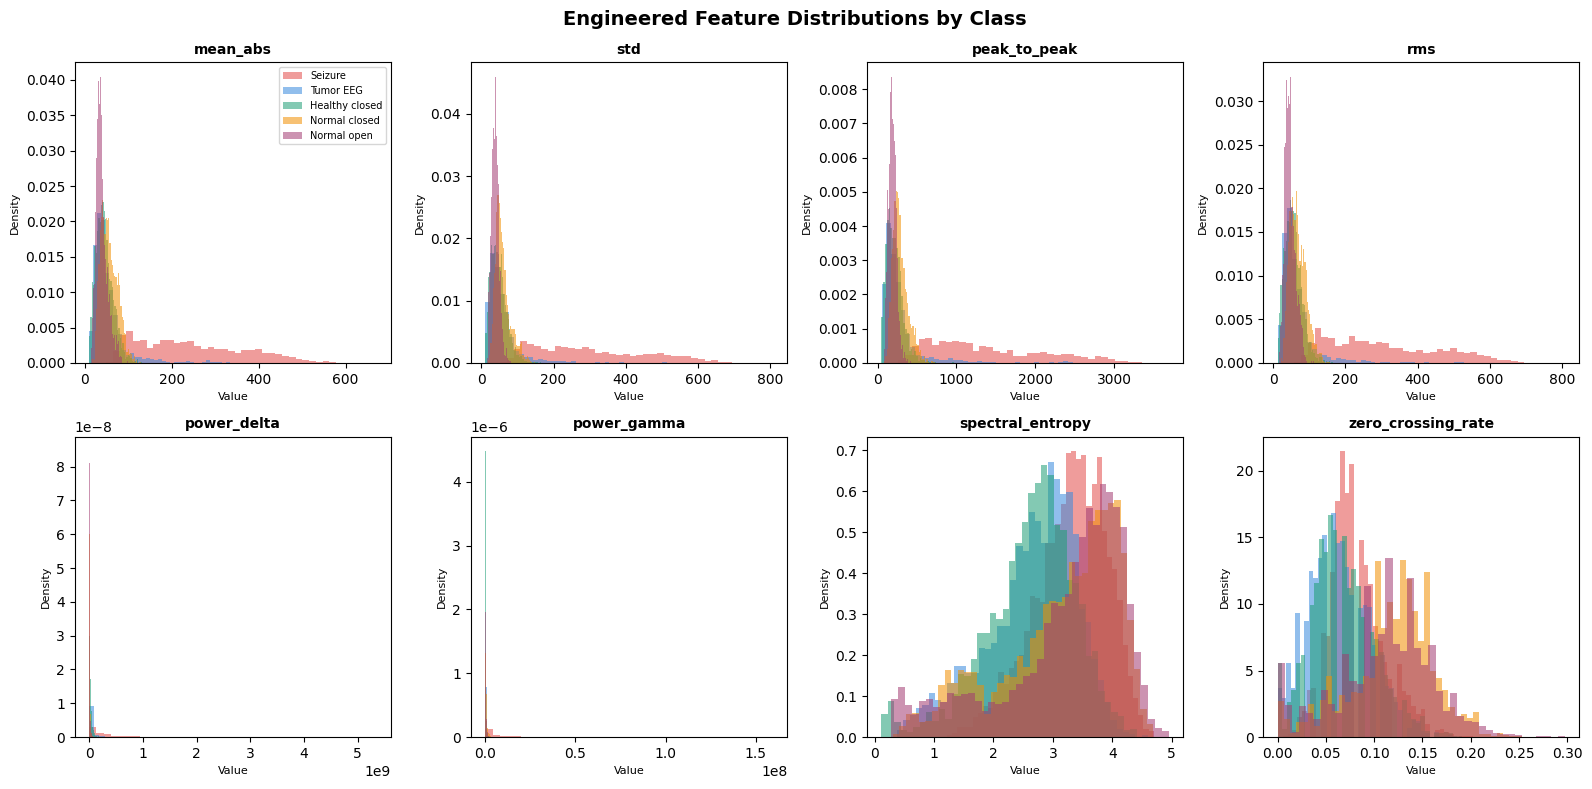

Saved: feature_distributions.png


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
fig.suptitle("Engineered Feature Distributions by Class", fontsize=14, fontweight='bold')

class_labels = {1:'Seizure', 2:'Tumor EEG', 3:'Healthy closed',
                4:'Normal closed', 5:'Normal open'}
colors_cls   = {1:'#E24B4A', 2:'#378ADD', 3:'#1D9E75', 4:'#F18F01', 5:'#A23B72'}

plot_feats = ['mean_abs','std','peak_to_peak','rms',
              'power_delta','power_gamma','spectral_entropy','zero_crossing_rate']

for i, feat in enumerate(plot_feats):
    ax = axes[i]
    feat_idx = feature_names_all.index(feat)
    for cls in sorted(np.unique(y_raw)):
        mask = y_raw == cls
        vals = X_combined[mask, feat_idx]
        ax.hist(vals, bins=40, alpha=0.55, label=class_labels[cls],
                color=colors_cls[cls], density=True)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_xlabel("Value", fontsize=8)
    ax.set_ylabel("Density", fontsize=8)
    if i == 0:
        ax.legend(fontsize=7, loc='upper right')

plt.tight_layout()
plt.savefig("feature_distributions.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_distributions.png")

## Step 3 · Train-Test Split (70/10/20)

> **Note:** Feature selection (CONSENSUS) is defined in Step 4. The validation and test sets will be projected into the selected feature space after Step 4.

In [11]:
# First split: 80% train+val, 20% test
X_tv_raw, X_test_raw, y_tv, y_test = train_test_split(
    X_combined, y_binary,
    test_size=0.2, stratify=y_binary, random_state=RANDOM_STATE
)

# Second split: 70% train, 10% val  (10/80 = 0.125 of train+val)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_tv_raw, y_tv,
    test_size=0.125, stratify=y_tv, random_state=RANDOM_STATE
)

print(f"Train     : {X_train_raw.shape[0]:,} samples ({X_train_raw.shape[0]/len(y_binary)*100:.0f}%)")
print(f"Validation: {X_val_raw.shape[0]:,} samples ({X_val_raw.shape[0]/len(y_binary)*100:.0f}%)")
print(f"Test      : {X_test_raw.shape[0]:,} samples ({X_test_raw.shape[0]/len(y_binary)*100:.0f}%)")

for split_name, y_split in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{split_name} class distribution:")
    print(pd.Series(y_split).value_counts().sort_index()
          .rename({0:'Non-Seizure (0)', 1:'Seizure (1)'}))

# Scale features — fit ONLY on train, transform all splits
scaler      = StandardScaler()
X_train_sc  = scaler.fit_transform(X_train_raw)
X_val_sc    = scaler.transform(X_val_raw)
X_test_sc   = scaler.transform(X_test_raw)

# Non-negative version for Chi2 (shift by train minimum)
train_min   = X_train_sc.min(axis=0)
X_train_nn  = X_train_sc - train_min
X_val_nn    = X_val_sc   - train_min
X_test_nn   = X_test_sc  - train_min

print("\nFeatures scaled with StandardScaler (fit on train only).")

Train     : 8,050 samples (70%)
Validation: 1,150 samples (10%)
Test      : 2,300 samples (20%)

Train class distribution:
Non-Seizure (0)    6440
Seizure (1)        1610
Name: count, dtype: int64

Validation class distribution:
Non-Seizure (0)    920
Seizure (1)        230
Name: count, dtype: int64

Test class distribution:
Non-Seizure (0)    1840
Seizure (1)         460
Name: count, dtype: int64

Features scaled with StandardScaler (fit on train only).


## Step 4 · Feature Selection

Consensus approach: a feature is selected if chosen by ≥ 2 of 4 methods.

In [12]:
K_BEST = 50

# ── 4a. Chi-Squared ──────────────────────────────────
print("Running Chi-Squared test...")
chi2_scores, chi2_pvals = chi2(X_train_nn, y_train)
chi2_df = pd.DataFrame({
    'Feature'   : feature_names_all,
    'Chi2_Score': chi2_scores,
    'p_value'   : chi2_pvals
}).sort_values('Chi2_Score', ascending=False)
chi2_selected = chi2_df.head(K_BEST)['Feature'].tolist()
print(f"Top-10 Chi2 features:")
print(chi2_df.head(10)[['Feature','Chi2_Score']].to_string(index=False))

Running Chi-Squared test...
Top-10 Chi2 features:
        Feature  Chi2_Score
       variance 9262.719325
hjorth_activity 9262.719325
    power_theta 8639.229283
    power_alpha 7848.471353
            std 7139.957818
     power_beta 6884.581230
   peak_to_peak 6873.296998
            iqr 6808.336456
    power_gamma 6762.621524
    line_length 6631.021452


In [13]:
# ── 4b. Mutual Information ───────────────────────────
print("Running Mutual Information...")
mi_scores = mutual_info_classif(X_train_sc, y_train, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({
    'Feature' : feature_names_all,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)
mi_selected = mi_df.head(K_BEST)['Feature'].tolist()
print("Top-10 MI features:")
print(mi_df.head(10).to_string(index=False))

Running Mutual Information...
Top-10 MI features:
        Feature  MI_Score
            std  0.401170
       variance  0.401086
hjorth_activity  0.401086
    power_theta  0.398568
            rms  0.396486
   peak_to_peak  0.396172
       mean_abs  0.392081
            iqr  0.383176
            min  0.376956
            p10  0.374539


In [14]:
# ── 4c. RFECV ────────────────────────────────────────
print("Running RFECV (this takes a few minutes)...")
rfecv_est = RandomForestClassifier(n_estimators=50, max_depth=8,
                                    class_weight='balanced',
                                    random_state=RANDOM_STATE, n_jobs=-1)
rfecv = RFECV(
    estimator              = rfecv_est,
    step                   = 1,
    cv                     = StratifiedKFold(3),
    scoring                = 'roc_auc',
    min_features_to_select = 20,
    n_jobs                 = -1
)
rfecv.fit(X_train_sc, y_train)
rfecv_selected = [feature_names_all[i] for i, s in enumerate(rfecv.support_) if s]
print(f"RFECV optimal features: {rfecv.n_features_}")
print(f"Selected (first 10): {rfecv_selected[:10]} ...")

Running RFECV (this takes a few minutes)...
RFECV optimal features: 35
Selected (first 10): ['X2', 'X146', 'X170', 'std', 'variance', 'skewness', 'kurtosis', 'min', 'max', 'peak_to_peak'] ...


In [15]:
# ── 4d. Sequential Feature Selection (SFS) ───────────
print("Running SFS forward selection (top 20 features)...")
sfs_est = LogisticRegression(max_iter=500, class_weight='balanced',
                              C=0.5, random_state=RANDOM_STATE)
sfs = SequentialFeatureSelector(
    sfs_est,
    n_features_to_select = 20,
    direction            = 'forward',
    scoring              = 'roc_auc',
    cv                   = StratifiedKFold(3),
    n_jobs               = -1
)
sfs.fit(X_train_sc, y_train)
sfs_selected = [feature_names_all[i] for i, s in enumerate(sfs.get_support()) if s]
print(f"SFS selected {len(sfs_selected)} features:")
print(sfs_selected)

Running SFS forward selection (top 20 features)...
SFS selected 20 features:
['X9', 'X86', 'X89', 'X141', 'X164', 'mean', 'std', 'iqr', 'zero_crossing_rate', 'line_length', 'hjorth_mobility', 'p10', 'p90', 'power_delta', 'power_theta', 'rel_theta', 'rel_alpha', 'rel_beta', 'theta_alpha_ratio', 'delta_beta_ratio']


In [16]:
# ── Consensus: features selected by ≥ 2 methods ──────
all_selections = {
    'Chi2' : set(chi2_selected),
    'MI'   : set(mi_selected),
    'RFECV': set(rfecv_selected),
    'SFS'  : set(sfs_selected),
}
vote_df = pd.DataFrame({
    feat: {method: int(feat in sel) for method, sel in all_selections.items()}
    for feat in feature_names_all
}).T
vote_df['Votes'] = vote_df.sum(axis=1)
vote_df = vote_df.sort_values('Votes', ascending=False)

CONSENSUS = vote_df.head(20).index.tolist()
print(f"Consensus features (top 20): {len(CONSENSUS)}")
print(f"\nTop-20 consensus features:")
print(vote_df.head(20).to_string())

feat_idx    = [feature_names_all.index(f) for f in CONSENSUS]
X_train_sel = X_train_sc[:, feat_idx]
X_val_sel   = X_val_sc[:,   feat_idx]
X_test_sel  = X_test_sc[:,  feat_idx]

print(f"\nFinal feature matrix shapes:")
print(f"  Train : {X_train_sel.shape}")
print(f"  Val   : {X_val_sel.shape}")
print(f"  Test  : {X_test_sel.shape}")

Consensus features (top 20): 20

Top-20 consensus features:
                    Chi2  MI  RFECV  SFS  Votes
std                    1   1      1    1      4
power_theta            1   1      1    1      4
p10                    1   1      1    1      4
p90                    1   1      1    1      4
iqr                    1   1      1    1      4
line_length            1   1      1    1      4
power_delta            1   1      1    1      4
min                    1   1      1    0      3
rms                    1   1      1    0      3
mean_abs               1   1      1    0      3
p75                    1   1      1    0      3
zero_crossing_rate     1   0      1    1      3
hjorth_activity        1   1      1    0      3
p25                    1   1      1    0      3
delta_beta_ratio       1   0      1    1      3
hjorth_mobility        1   0      1    1      3
rel_theta              1   0      1    1      3
power_gamma            1   1      1    0      3
power_beta             1   1

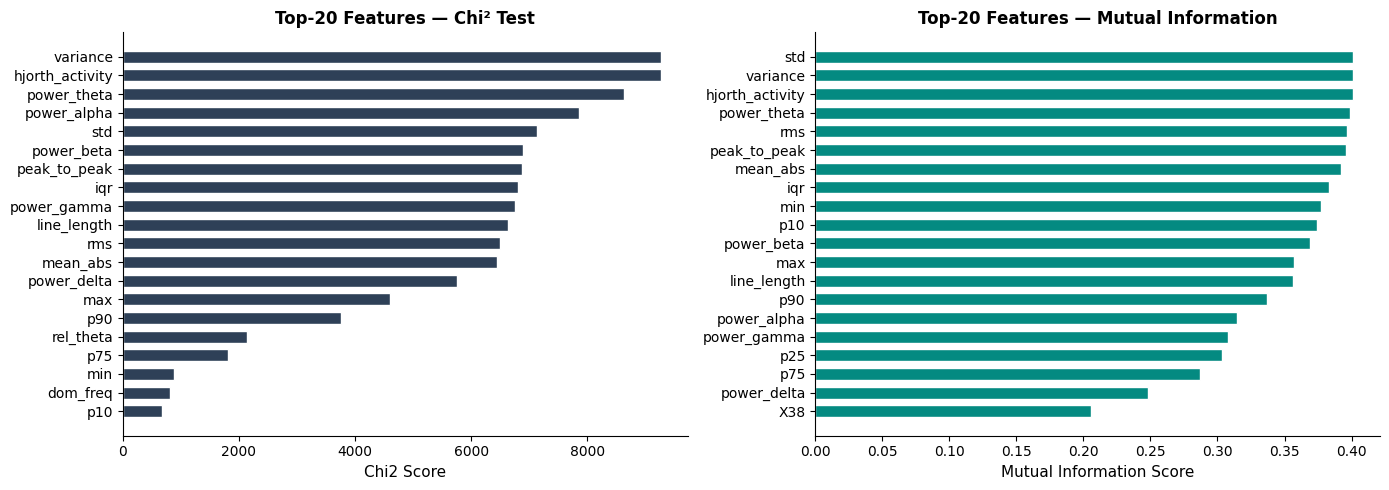

Saved: feature_selection.png


In [17]:
# Chi2 and MI top-20 bar charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
top20_chi2 = chi2_df.head(20)
ax.barh(top20_chi2['Feature'], top20_chi2['Chi2_Score'],
        color=PALETTE[0], edgecolor='white', height=0.65)
ax.set_xlabel('Chi2 Score', fontsize=11)
ax.set_title('Top-20 Features — Chi² Test', fontsize=12, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.invert_yaxis()

ax = axes[1]
top20_mi = mi_df.head(20)
ax.barh(top20_mi['Feature'], top20_mi['MI_Score'],
        color=PALETTE[1], edgecolor='white', height=0.65)
ax.set_xlabel('Mutual Information Score', fontsize=11)
ax.set_title('Top-20 Features — Mutual Information', fontsize=12, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("feature_selection.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_selection.png")

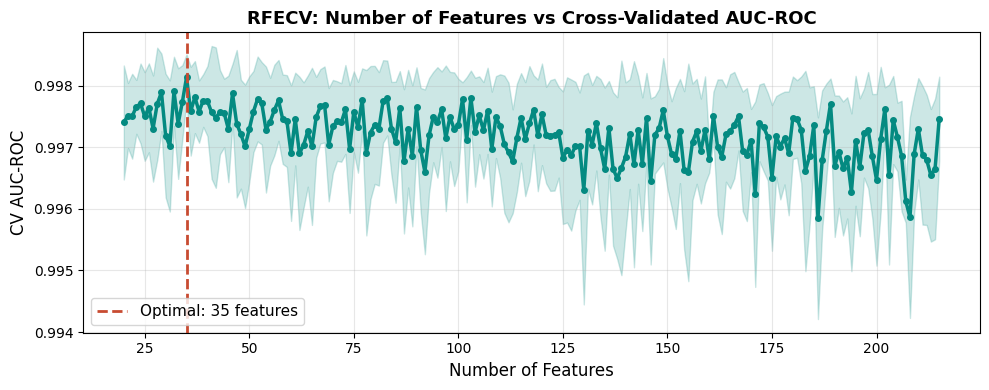

Saved: rfecv_curve.png


In [18]:
# FIX: Correctly compute n_range using step size from RFECV
cv_res  = rfecv.cv_results_
mean_sc = cv_res['mean_test_score']
std_sc  = cv_res['std_test_score']

# n_range must account for step size
step = rfecv.step if isinstance(rfecv.step, int) else 1
n_range = range(rfecv.min_features_to_select,
                rfecv.min_features_to_select + len(mean_sc) * step,
                step)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(list(n_range), mean_sc, color='#048A81', lw=2.5, marker='o', markersize=4)
ax.fill_between(list(n_range), mean_sc - std_sc, mean_sc + std_sc,
                alpha=0.2, color='#048A81')
ax.axvline(rfecv.n_features_, linestyle='--', color='#C84B31', lw=2,
           label=f"Optimal: {rfecv.n_features_} features")
ax.set_xlabel('Number of Features', fontsize=12)
ax.set_ylabel('CV AUC-ROC', fontsize=12)
ax.set_title('RFECV: Number of Features vs Cross-Validated AUC-ROC',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("rfecv_curve.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: rfecv_curve.png")

## Step 5 · Data Balancing (SMOTETomek)

In [19]:
print(f"Before balancing:")
print(f"  Non-Seizure: {(y_train==0).sum()}")
print(f"  Seizure    : {(y_train==1).sum()}")
print(f"  Ratio      : {(y_train==0).sum()/(y_train==1).sum():.1f}:1")

if IMBLEARN_AVAILABLE:
    smt = SMOTETomek(random_state=RANDOM_STATE)
    X_bal, y_bal = smt.fit_resample(X_train_sel, y_train)
    print(f"\nSMOTETomek (imbalanced-learn):")
else:
    print("\nApplying manual SMOTE...")

    def manual_smote(X, y, random_state=42):
        rng   = np.random.default_rng(random_state)
        X_maj = X[y == 0]; X_min = X[y == 1]
        n_gen = len(X_maj) - len(X_min)
        k     = min(5, len(X_min) - 1)
        syn   = []
        for _ in range(n_gen):
            idx  = rng.integers(0, len(X_min))
            samp = X_min[idx]
            dists = np.linalg.norm(X_min - samp, axis=1)
            nn_idx = np.argsort(dists)[1:k+1]
            nn   = X_min[rng.choice(nn_idx)]
            lam  = rng.random()
            syn.append(samp + lam * (nn - samp))
        X_s = np.vstack([X_maj, X_min, np.array(syn)])
        y_s = np.concatenate([np.zeros(len(X_maj), dtype=int),
                               np.ones(len(X_min), dtype=int),
                               np.ones(n_gen, dtype=int)])
        idx = rng.permutation(len(y_s))
        return X_s[idx], y_s[idx]

    def tomek_links(X, y):
        from sklearn.neighbors import NearestNeighbors
        nn = NearestNeighbors(n_neighbors=2).fit(X)
        _, inds = nn.kneighbors(X)
        keep = np.ones(len(y), dtype=bool)
        for i in range(len(y)):
            j = inds[i, 1]
            if y[i] != y[j]:
                if y[i] == 0: keep[i] = False
                else: keep[j] = False
        return X[keep], y[keep]

    X_smote, y_smote = manual_smote(X_train_sel, y_train, RANDOM_STATE)
    print(f"  After SMOTE  : {np.bincount(y_smote)}")
    print("Applying Tomek link cleaning...")
    X_bal, y_bal = tomek_links(X_smote, y_smote)

print(f"\nAfter balancing:")
print(f"  Non-Seizure: {(y_bal==0).sum()}")
print(f"  Seizure    : {(y_bal==1).sum()}")
print(f"  Total      : {len(y_bal)}")

Before balancing:
  Non-Seizure: 6440
  Seizure    : 1610
  Ratio      : 4.0:1

SMOTETomek (imbalanced-learn):

After balancing:
  Non-Seizure: 6439
  Seizure    : 6439
  Total      : 12878


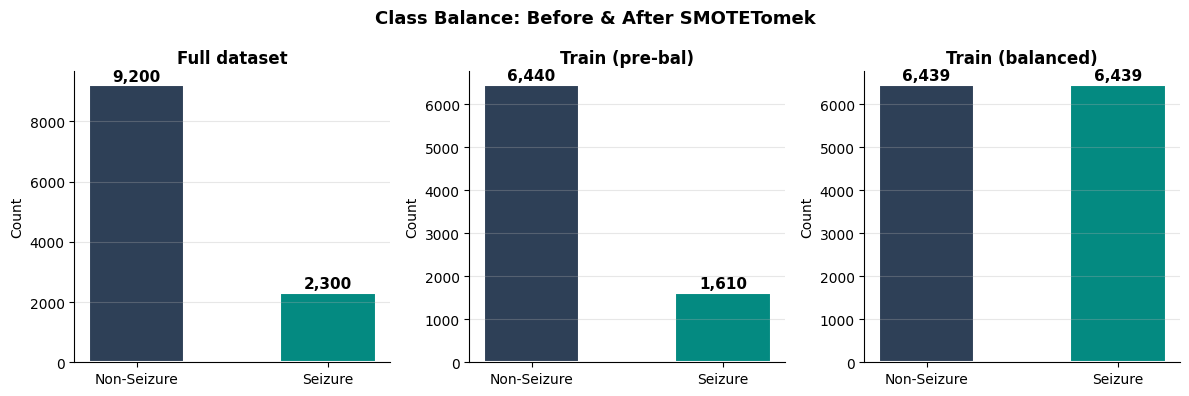

Saved: class_balance.png


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
labels = ['Non-Seizure', 'Seizure']

datasets = [
    ('Full dataset',     [(y_binary==0).sum(), (y_binary==1).sum()]),
    ('Train (pre-bal)',  [(y_train==0).sum(),   (y_train==1).sum()]),
    ('Train (balanced)', [(y_bal==0).sum(),      (y_bal==1).sum()]),
]
for ax, (title, counts) in zip(axes, datasets):
    bars = ax.bar(labels, counts, color=['#2E4057','#048A81'],
                  edgecolor='white', linewidth=1.5, width=0.5)
    for bar, c in zip(bars, counts):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+50,
                f'{c:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Count', fontsize=10)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Class Balance: Before & After SMOTETomek', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("class_balance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: class_balance.png")

## Steps 6 & 7 · Model Training & Hyperparameter Tuning

All 11 models run in order [1/11]–[11/11].

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, fit=True):
    """Train (optionally) and evaluate a model; return metrics dict."""
    if fit:
        model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = (model.predict_proba(X_te)[:, 1]
              if hasattr(model, 'predict_proba')
              else model.decision_function(X_te))
    metrics = {
        'Model'    : name,
        'Accuracy' : accuracy_score(y_te, y_pred),
        'Recall'   : recall_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'F1'       : f1_score(y_te, y_pred),
        'F2'       : fbeta_score(y_te, y_pred, beta=2),
        'AUC-ROC'  : roc_auc_score(y_te, y_prob),
        '_model'   : model,
        '_y_prob'  : y_prob,
        '_y_pred'  : y_pred,
    }
    print(f"  {name:<30} AUC={metrics['AUC-ROC']:.4f}  F1={metrics['F1']:.4f}  Recall={metrics['Recall']:.4f}")
    return metrics

print("=" * 65)
print("  Model Training with RandomizedSearchCV Tuning")
print("=" * 65)

  Model Training with RandomizedSearchCV Tuning


In [22]:
# ── 1/11. Logistic Regression ─────────────────────────────────
print("\n[1/11] Logistic Regression")
lr_params = {
    'C'      : [0.001, 0.01, 0.1, 0.5, 1, 5, 10, 50],
    'solver' : ['lbfgs', 'saga'],
    'penalty': ['l2']
}
lr_cv = RandomizedSearchCV(
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    lr_params, n_iter=12, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
lr_cv.fit(X_bal, y_bal)
best_lr = lr_cv.best_estimator_
print(f"  Best params: {lr_cv.best_params_}")
results.append(evaluate_model('Logistic Regression', best_lr, X_bal, y_bal, X_test_sel, y_test, fit=False))


[1/11] Logistic Regression


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which 

  Best params: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 50}
  Logistic Regression            AUC=0.9954  F1=0.9419  Recall=0.9696


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [23]:
# ── 2/11. Decision Tree ─────────────────────────────────
print("\n[2/11] Decision Tree")
dt_params = {
    'max_depth'       : [3, 5, 8, 12, 15, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion'       : ['gini', 'entropy'],
    'max_features'    : ['sqrt', 'log2', None]
}
dt_cv = RandomizedSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    dt_params, n_iter=15, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
dt_cv.fit(X_bal, y_bal)
best_dt = dt_cv.best_estimator_
print(f"  Best params: {dt_cv.best_params_}")
results.append(evaluate_model('Decision Tree', best_dt, X_bal, y_bal, X_test_sel, y_test, fit=False))


[2/11] Decision Tree
  Best params: {'min_samples_leaf': 10, 'max_features': None, 'max_depth': 5, 'criterion': 'entropy'}
  Decision Tree                  AUC=0.9953  F1=0.9347  Recall=0.9957


In [24]:
# ── 3/11. Random Forest ─────────────────────────────────
print("\n[3/11] Random Forest")
rf_params = {
    'n_estimators'    : [100, 200, 300, 500],
    'max_depth'       : [5, 10, 15, 20, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features'    : ['sqrt', 'log2', 0.3, 0.5]
}
rf_cv = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    rf_params, n_iter=5, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_cv.fit(X_bal, y_bal)
best_rf = rf_cv.best_estimator_
print(f"  Best params: {rf_cv.best_params_}")
results.append(evaluate_model('Random Forest', best_rf, X_bal, y_bal, X_test_sel, y_test, fit=False))


[3/11] Random Forest
  Best params: {'n_estimators': 500, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 15}
  Random Forest                  AUC=0.9980  F1=0.9574  Recall=0.9761


In [25]:
# ── 4/11. Gradient Boosting ─────────────────────────────────
print("\n[4/11] Gradient Boosting")
gb_params = {
    'n_estimators'    : [100, 200, 300],
    'learning_rate'   : [0.01, 0.05, 0.1, 0.2],
    'max_depth'       : [3, 4, 5, 6],
    'subsample'       : [0.7, 0.8, 0.9, 1.0],
    'min_samples_leaf': [1, 5, 10]
}
gb_cv = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    gb_params, n_iter=5, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
gb_cv.fit(X_bal, y_bal)
best_gb = gb_cv.best_estimator_
print(f"  Best params: {gb_cv.best_params_}")
results.append(evaluate_model('Gradient Boosting', best_gb, X_bal, y_bal, X_test_sel, y_test, fit=False))


[4/11] Gradient Boosting
  Best params: {'subsample': 0.9, 'n_estimators': 200, 'min_samples_leaf': 5, 'max_depth': 6, 'learning_rate': 0.05}
  Gradient Boosting              AUC=0.9981  F1=0.9593  Recall=0.9739


In [ ]:
# ── 5/11. HistGradientBoosting ─────────────────────────────────
print("\n[5/11] HistGradientBoosting")
hgb_params = {
    'max_iter'          : [100, 200, 300, 500],
    'learning_rate'     : [0.01, 0.05, 0.1, 0.2],
    'max_depth'         : [3, 5, 8, 10, None],
    'min_samples_leaf'  : [10, 20, 50],
    'l2_regularization' : [0.0, 0.1, 0.5, 1.0],
    'max_bins'          : [128, 255]
}
hgb_cv = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    hgb_params, n_iter=20, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
hgb_cv.fit(X_bal, y_bal)
best_hgb = hgb_cv.best_estimator_
print(f"  Best params: {hgb_cv.best_params_}")
results.append(evaluate_model('HistGradientBoosting', best_hgb, X_bal, y_bal, X_test_sel, y_test, fit=False))


[5/11] HistGradientBoosting


In [27]:
# ── 6/11. Extra Trees ─────────────────────────────────
print("\n[6/11] Extra Trees")
et_params = {
    'n_estimators'    : [100, 200, 300, 500],
    'max_depth'       : [5, 10, 15, None],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features'    : ['sqrt', 'log2', 0.3, 0.5]
}
et_cv = RandomizedSearchCV(
    ExtraTreesClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    et_params, n_iter=20, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
et_cv.fit(X_bal, y_bal)
best_et = et_cv.best_estimator_
print(f"  Best params: {et_cv.best_params_}")
results.append(evaluate_model('Extra Trees', best_et, X_bal, y_bal, X_test_sel, y_test, fit=False))

  Best params: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}
  Extra Trees                    AUC=0.9986  F1=0.9643  Recall=0.9696


In [28]:
# ── 7/11. AdaBoost ─────────────────────────────────
print("\n[7/11] AdaBoost")
ada_params = {
    'n_estimators' : [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
    'algorithm'    : ['SAMME']   # SAMME.R removed in sklearn >=1.6
}
ada_cv = RandomizedSearchCV(
    AdaBoostClassifier(random_state=RANDOM_STATE),
    ada_params, n_iter=12, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
ada_cv.fit(X_bal, y_bal)
best_ada = ada_cv.best_estimator_
print(f"  Best params: {ada_cv.best_params_}")
results.append(evaluate_model('AdaBoost', best_ada, X_bal, y_bal, X_test_sel, y_test, fit=False))


[7/11] AdaBoost


/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 

  Best params: {'n_estimators': 200, 'learning_rate': 1.0, 'algorithm': 'SAMME'}
  AdaBoost                       AUC=0.9983  F1=0.9487  Recall=0.9848


In [29]:
# ── 8/11. K-Nearest Neighbors ─────────────────────────────────
print("\n[8/11] K-Nearest Neighbors")
knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights'    : ['uniform', 'distance'],
    'metric'     : ['euclidean', 'manhattan']
}
knn_cv = RandomizedSearchCV(
    KNeighborsClassifier(n_jobs=-1),
    knn_params, n_iter=10, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
knn_cv.fit(X_bal, y_bal)
best_knn = knn_cv.best_estimator_
print(f"  Best params: {knn_cv.best_params_}")
results.append(evaluate_model('K-Nearest Neighbors', best_knn, X_bal, y_bal, X_test_sel, y_test, fit=False))


[8/11] K-Nearest Neighbors
  Best params: {'weights': 'uniform', 'n_neighbors': 11, 'metric': 'euclidean'}
  K-Nearest Neighbors            AUC=0.9930  F1=0.9433  Recall=0.9761


In [30]:
# ── 9/11. Support Vector Classifier ─────────────────────────────────
print("\n[9/11] Support Vector Classifier")
svc_params = {
    'C'     : [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma' : ['scale', 'auto', 0.1, 1]
}
svc_cv = RandomizedSearchCV(
    SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE),
    svc_params, n_iter=10, cv=cv, scoring='roc_auc',
    random_state=RANDOM_STATE, n_jobs=-1
)
svc_cv.fit(X_bal, y_bal)
best_svc = svc_cv.best_estimator_
print(f"  Best params: {svc_cv.best_params_}")
results.append(evaluate_model('SVC', best_svc, X_bal, y_bal, X_test_sel, y_test, fit=False))


[9/11] Support Vector Classifier
  Best params: {'kernel': 'rbf', 'gamma': 'scale', 'C': 100}
  SVC                            AUC=0.9970  F1=0.9596  Recall=0.9804


In [31]:
# ── 10/11. Voting Ensemble ───────────────────────────
print("\n[10/11] Voting Ensemble (soft)")
voting = VotingClassifier(
    estimators=[
        ('lr',  best_lr),
        ('rf',  best_rf),
        ('gb',  best_gb),
        ('hgb', best_hgb),
        ('et',  best_et),
    ],
    voting='soft', n_jobs=-1
)
results.append(evaluate_model('Voting Ensemble', voting, X_bal, y_bal, X_test_sel, y_test))


[10/11] Voting Ensemble (soft)
  Voting Ensemble                AUC=0.9985  F1=0.9658  Recall=0.9826


In [32]:
# ── 11/11. Stacking Ensemble ─────────────────────────
print("\n[11/11] Stacking Ensemble")
stacking = StackingClassifier(
    estimators=[
        ('rf',  best_rf),
        ('gb',  best_gb),
        ('hgb', best_hgb),
    ],
    final_estimator=LogisticRegression(
        max_iter=1000, C=1, class_weight='balanced', random_state=RANDOM_STATE
    ),
    cv=StratifiedKFold(3),
    passthrough=False,
    n_jobs=-1
)
results.append(evaluate_model('Stacking Ensemble', stacking, X_bal, y_bal, X_test_sel, y_test))

print("\n✓ All 11 models trained and evaluated.")


[11/11] Stacking Ensemble
  Stacking Ensemble              AUC=0.9983  F1=0.9614  Recall=0.9739

✓ All 11 models trained and evaluated.


## Step 8 · Comprehensive Evaluation & Visualisations

In [33]:
metric_cols = ['Model','Accuracy','Recall','Precision','F1','F2','AUC-ROC']
results_df  = (pd.DataFrame(results)[metric_cols]
               .set_index('Model')
               .sort_values('AUC-ROC', ascending=False))

print("\n" + "="*65)
print("  FINAL LEADERBOARD")
print("="*65)
print(results_df.round(4).to_string())


  FINAL LEADERBOARD
                      Accuracy  Recall  Precision      F1      F2  AUC-ROC
Model                                                                     
Extra Trees             0.9857  0.9696     0.9591  0.9643  0.9675   0.9986
HistGradientBoosting    0.9857  0.9804     0.9495  0.9647  0.9741   0.9985
Voting Ensemble         0.9861  0.9826     0.9496  0.9658  0.9758   0.9985
AdaBoost                0.9787  0.9848     0.9152  0.9487  0.9700   0.9983
Stacking Ensemble       0.9843  0.9739     0.9492  0.9614  0.9689   0.9983
Gradient Boosting       0.9835  0.9739     0.9451  0.9593  0.9680   0.9981
Random Forest           0.9826  0.9761     0.9393  0.9574  0.9685   0.9980
SVC                     0.9835  0.9804     0.9396  0.9596  0.9720   0.9970
Logistic Regression     0.9761  0.9696     0.9158  0.9419  0.9583   0.9954
Decision Tree           0.9722  0.9957     0.8808  0.9347  0.9703   0.9953
K-Nearest Neighbors     0.9765  0.9761     0.9126  0.9433  0.9627   0.9930


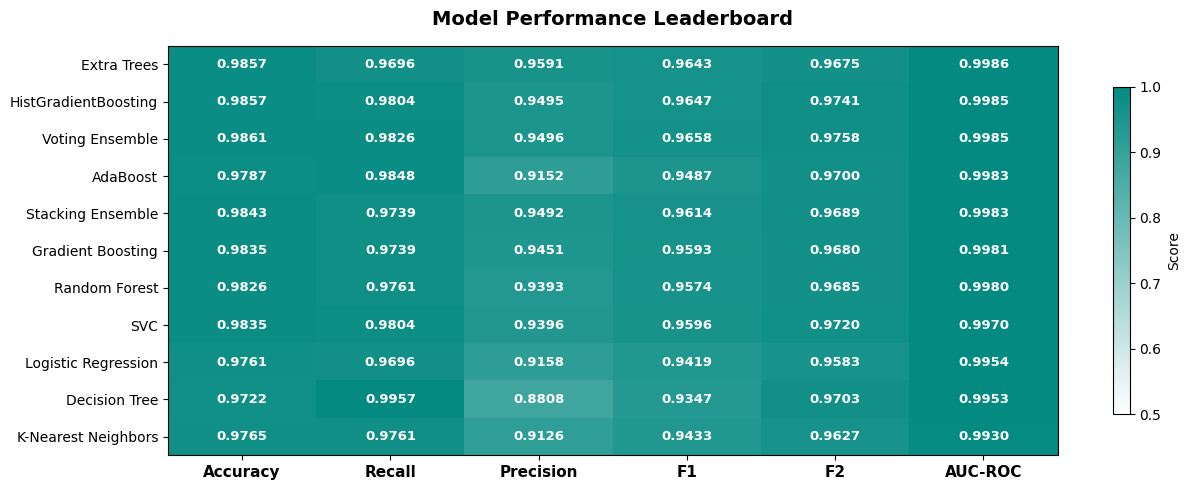

Saved: leaderboard_heatmap.png


In [34]:
fig, ax = plt.subplots(figsize=(13, 5))
data_mat = results_df.select_dtypes(include=np.number).values.astype(float)
cmap = LinearSegmentedColormap.from_list('teal', ['#ffffff','#048A81'])
im   = ax.imshow(data_mat, cmap=cmap, aspect='auto', vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(results_df.columns)))
ax.set_xticklabels(results_df.columns, fontsize=11, fontweight='bold')
ax.set_yticks(range(len(results_df.index)))
ax.set_yticklabels(results_df.index, fontsize=10)
for i in range(len(results_df.index)):
    for j in range(len(results_df.columns)):
        v   = data_mat[i, j]
        col = 'white' if v > 0.77 else '#1a1a2e'
        ax.text(j, i, f'{v:.4f}', ha='center', va='center',
                fontsize=9.5, color=col, fontweight='bold')
plt.colorbar(im, ax=ax, shrink=0.8, label='Score')
ax.set_title('Model Performance Leaderboard', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("leaderboard_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: leaderboard_heatmap.png")

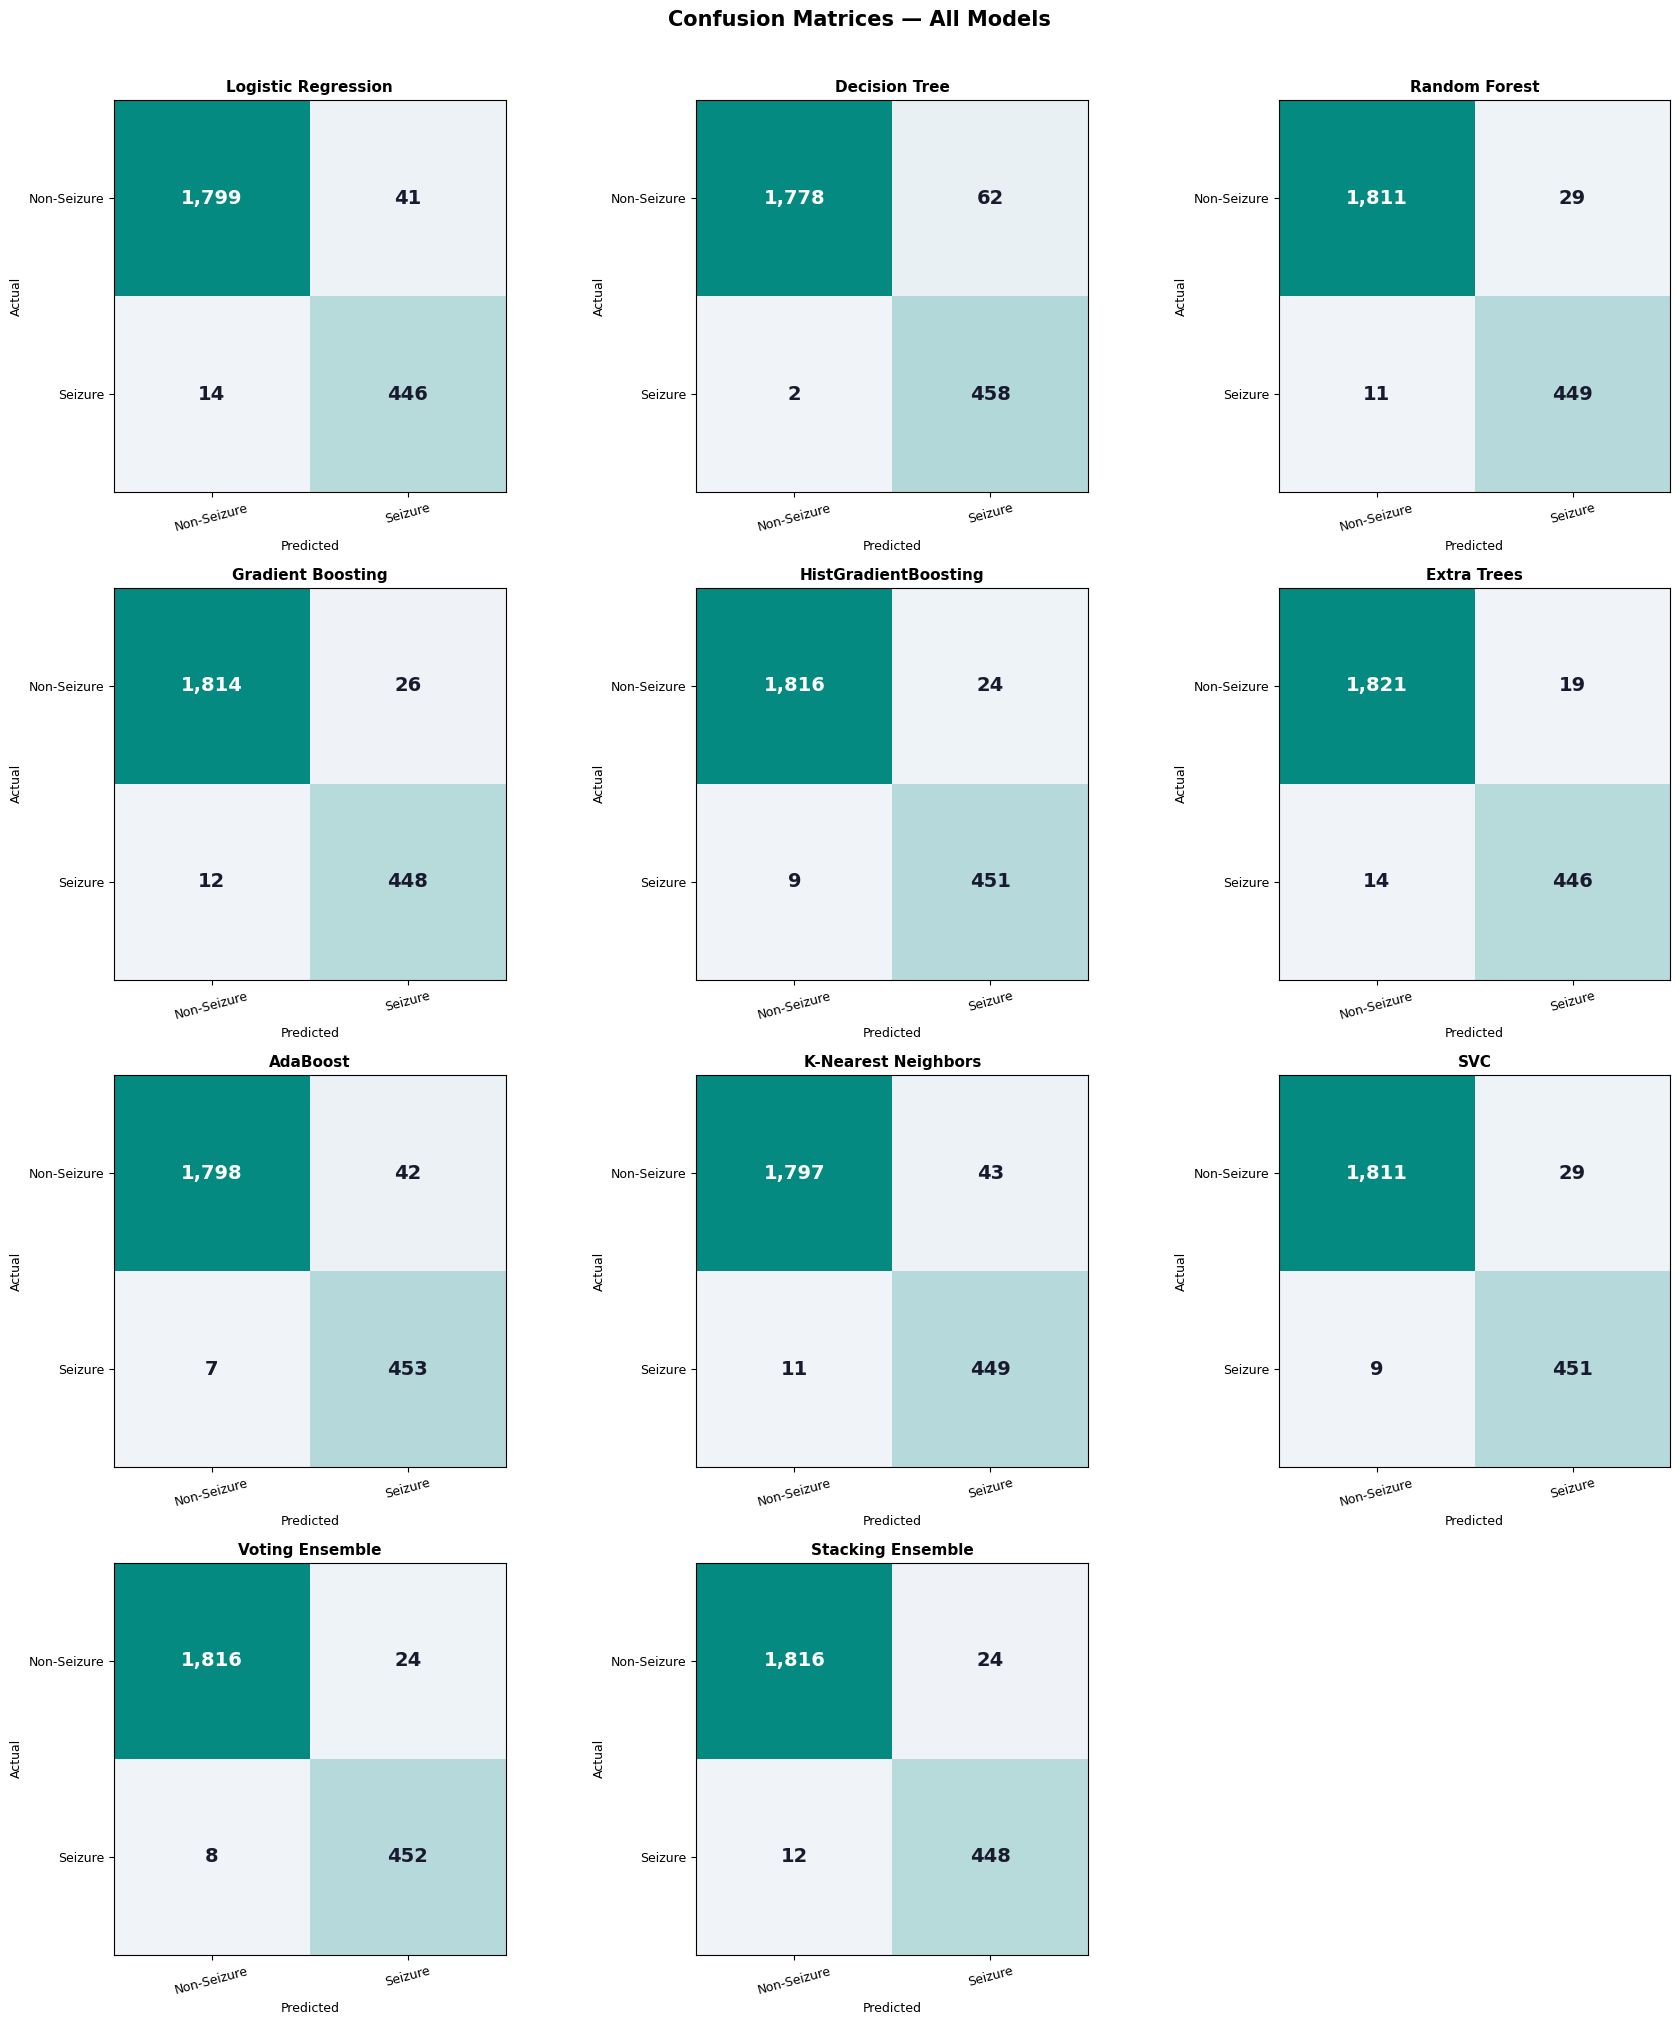

Saved: confusion_matrices.png


In [35]:
# Figure 2: Confusion Matrices
n_models = len(results)
ncols = 3
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 5*nrows))
axes = axes.flatten()

cmap_cm = LinearSegmentedColormap.from_list('cm', ['#f0f4f8','#048A81'])

for idx, r in enumerate(results):
    cm  = confusion_matrix(y_test, r['_y_pred'])
    ax  = axes[idx]
    ax.imshow(cm, interpolation='nearest', cmap=cmap_cm)
    ax.set_title(r['Model'], fontsize=11, fontweight='bold')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Non-Seizure','Seizure'], fontsize=9, rotation=15)
    ax.set_yticklabels(['Non-Seizure','Seizure'], fontsize=9)
    thresh = cm.max() / 2
    for i, j in itertools.product(range(2), range(2)):
        ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                fontsize=14, fontweight='bold',
                color='white' if cm[i,j] > thresh else '#1a1a2e')
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('Actual',    fontsize=9)

for idx in range(n_models, len(axes)):
    axes[idx].set_visible(False)

fig.suptitle('Confusion Matrices — All Models', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrices.png")

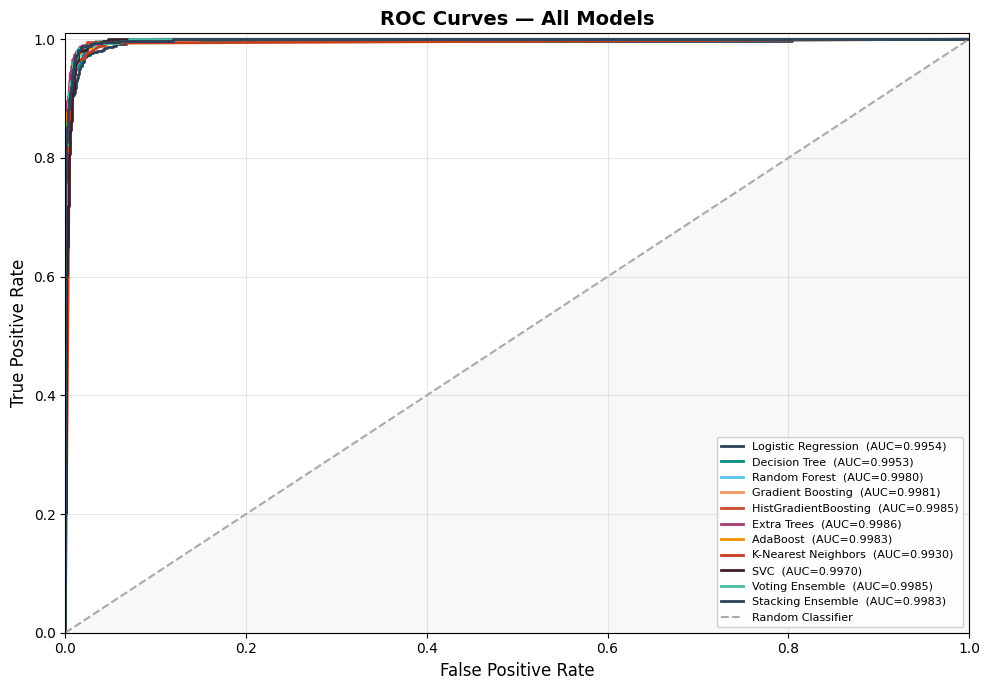

Saved: roc_curves.png


In [36]:
# Figure 3: ROC Curves
fig, ax = plt.subplots(figsize=(10, 7))
for idx, r in enumerate(results):
    fpr, tpr, _ = roc_curve(y_test, r['_y_prob'])
    ax.plot(fpr, tpr, lw=2, color=PALETTE[idx % len(PALETTE)],
            label=f"{r['Model']}  (AUC={r['AUC-ROC']:.4f})")

ax.plot([0,1],[0,1], '--', color='#aaaaaa', lw=1.5, label='Random Classifier')
ax.fill_between([0,1],[0,1], alpha=0.05, color='gray')
ax.set_xlim([0,1]); ax.set_ylim([0,1.01])
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate',  fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: roc_curves.png")

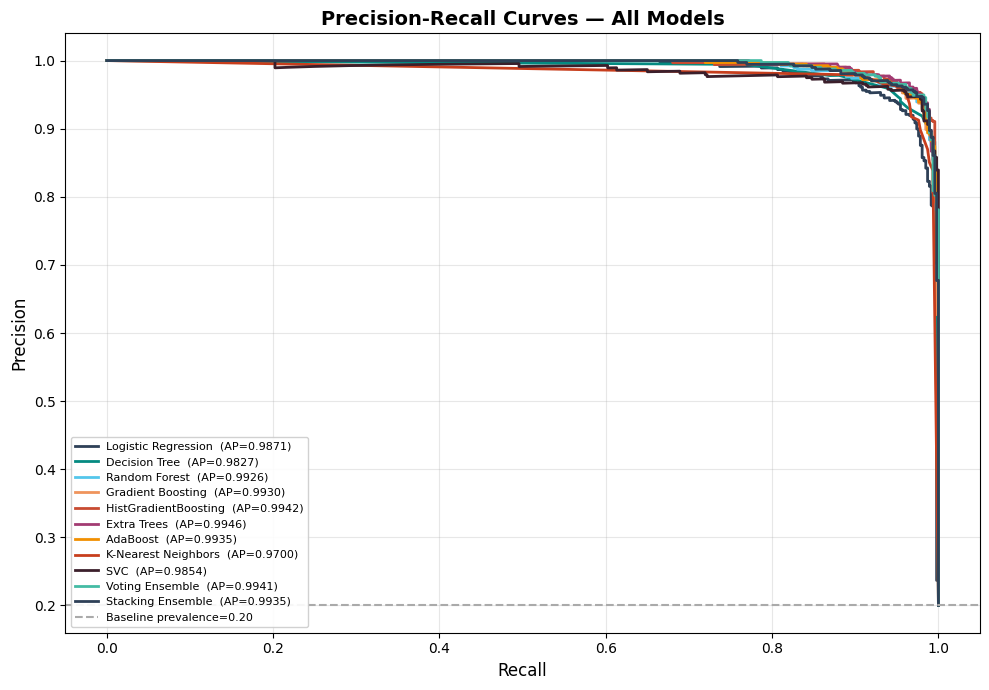

Saved: pr_curves.png


In [37]:
# Figure 4: Precision-Recall Curves
fig, ax = plt.subplots(figsize=(10, 7))
baseline = y_test.mean()
for idx, r in enumerate(results):
    prec, rec, _ = precision_recall_curve(y_test, r['_y_prob'])
    ap = average_precision_score(y_test, r['_y_prob'])
    ax.plot(rec, prec, lw=2, color=PALETTE[idx % len(PALETTE)],
            label=f"{r['Model']}  (AP={ap:.4f})")

ax.axhline(baseline, linestyle='--', color='#aaaaaa', lw=1.5,
           label=f'Baseline prevalence={baseline:.2f}')
ax.set_xlabel('Recall',    fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=8, framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("pr_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pr_curves.png")

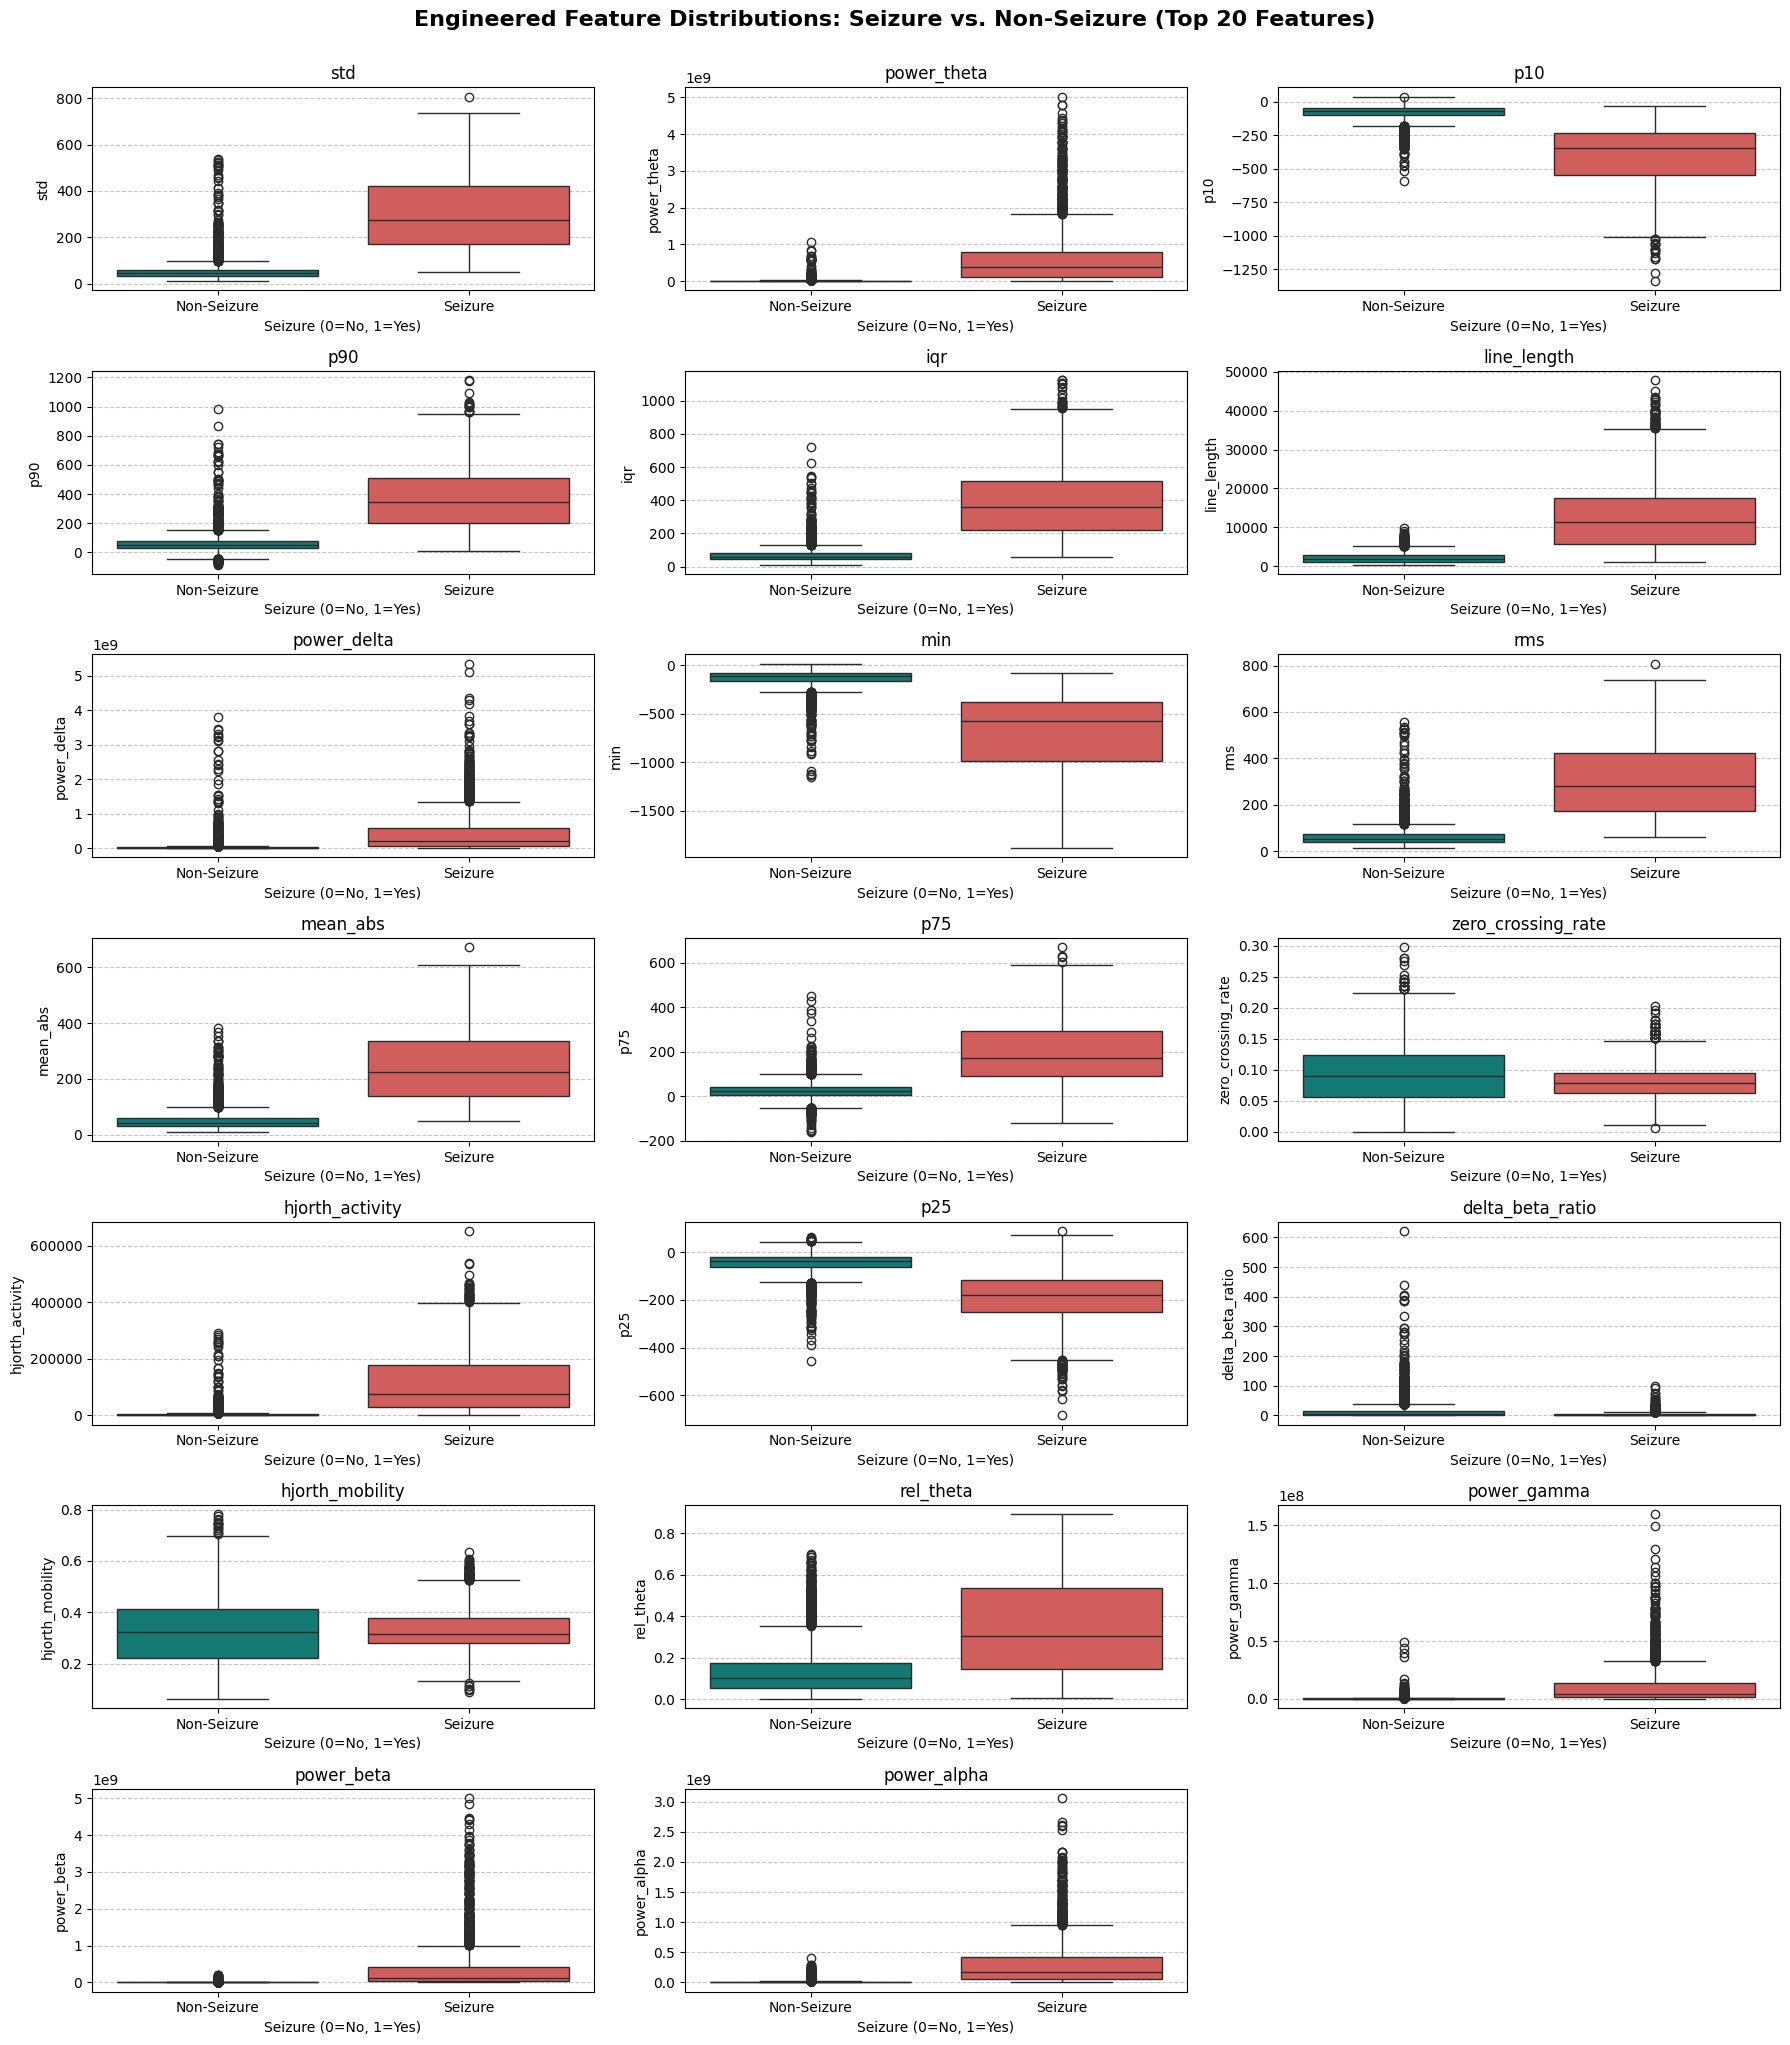

Saved: engineered_features_boxplots_top20.png


In [38]:
# Figure 5: Engineered Feature Box Plots
df_eng_target = X_eng.copy()
df_eng_target['Seizure'] = y_binary

# Updated to use all 20 consensus features
box_plot_features = CONSENSUS

plt.figure(figsize=(18, 20)) # Adjusted figure size to accommodate more plots
for i, feature in enumerate(box_plot_features):
    plt.subplot(7, 3, i + 1) # Adjusted subplot grid (7 rows, 3 columns) for 20 plots
    sns.boxplot(x='Seizure', y=feature, data=df_eng_target,
                palette=['#048A81', '#E24B4A'])
    plt.title(f'{feature}', fontsize=12)
    plt.xlabel('Seizure (0=No, 1=Yes)', fontsize=10)
    plt.ylabel(feature, fontsize=10)
    plt.xticks(ticks=[0, 1], labels=['Non-Seizure', 'Seizure'])
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.suptitle('Engineered Feature Distributions: Seizure vs. Non-Seizure (Top 20 Features)',
             y=1.02, fontsize=16, fontweight='bold')
plt.savefig("engineered_features_boxplots_top20.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: engineered_features_boxplots_top20.png")

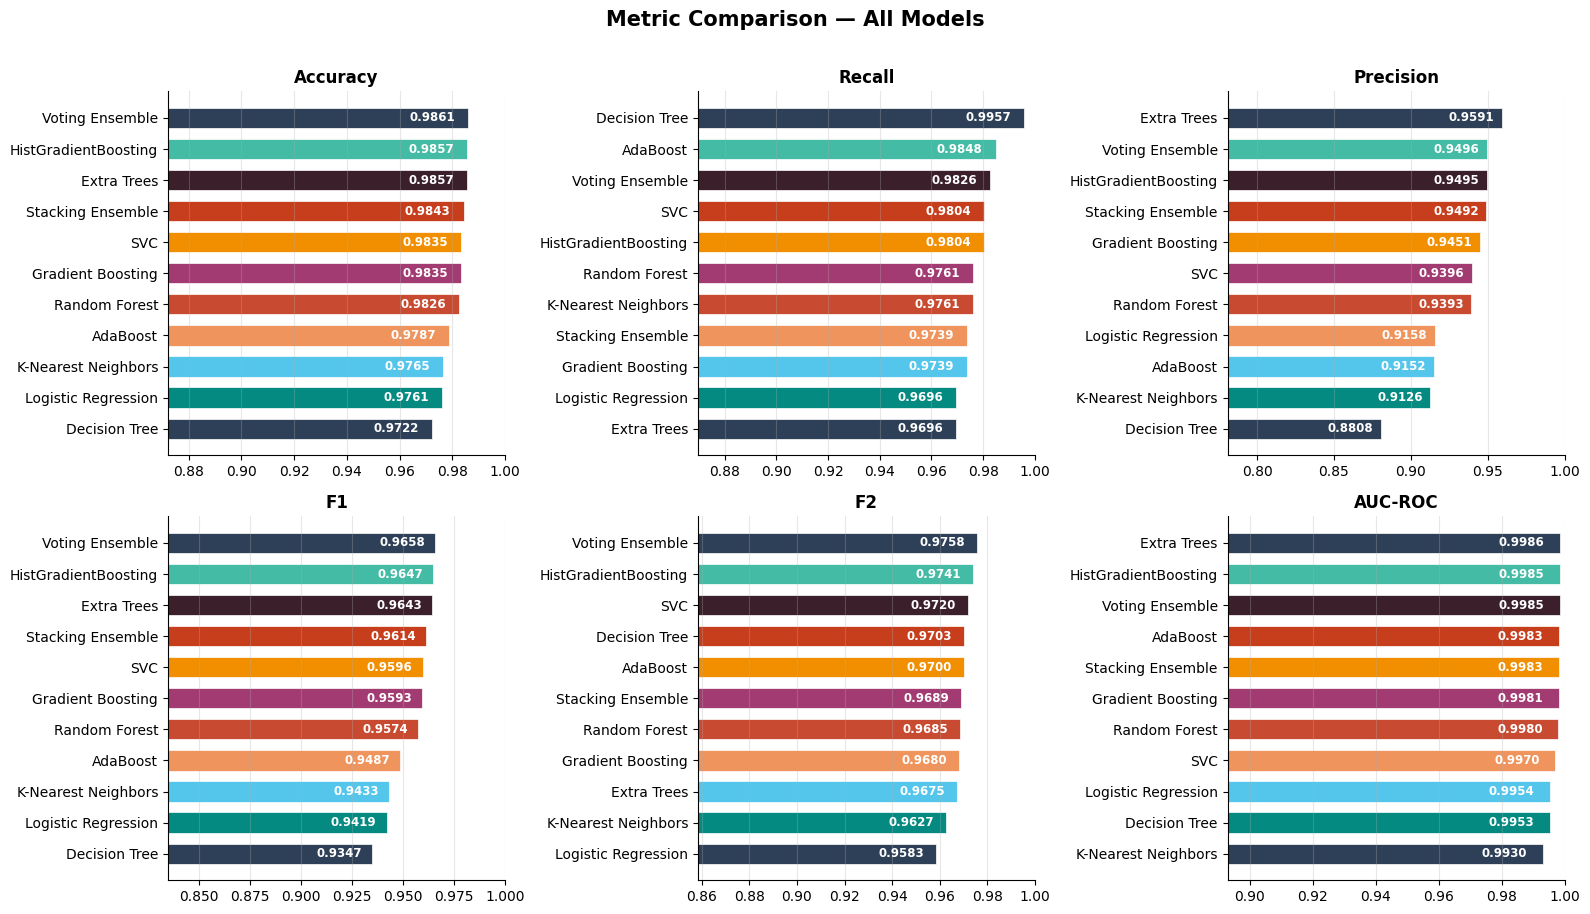

Saved: metric_comparison.png


In [39]:
# Figure 6: Metric Comparison Bar Charts
metrics_to_plot = ['Accuracy','Recall','Precision','F1','F2','AUC-ROC']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):
    ax  = axes[i]
    sub = results_df[metric].sort_values(ascending=True)
    bars = ax.barh(sub.index, sub.values,
                   color=[PALETTE[j % len(PALETTE)] for j in range(len(sub))],
                   edgecolor='white', linewidth=0.5, height=0.65)
    for bar, val in zip(bars, sub.values):
        ax.text(val - 0.005, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', ha='right',
                fontsize=8.5, color='white', fontweight='bold')
    ax.set_xlim(max(0, sub.min()-0.1), 1.0)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('Metric Comparison — All Models', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig("metric_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: metric_comparison.png")

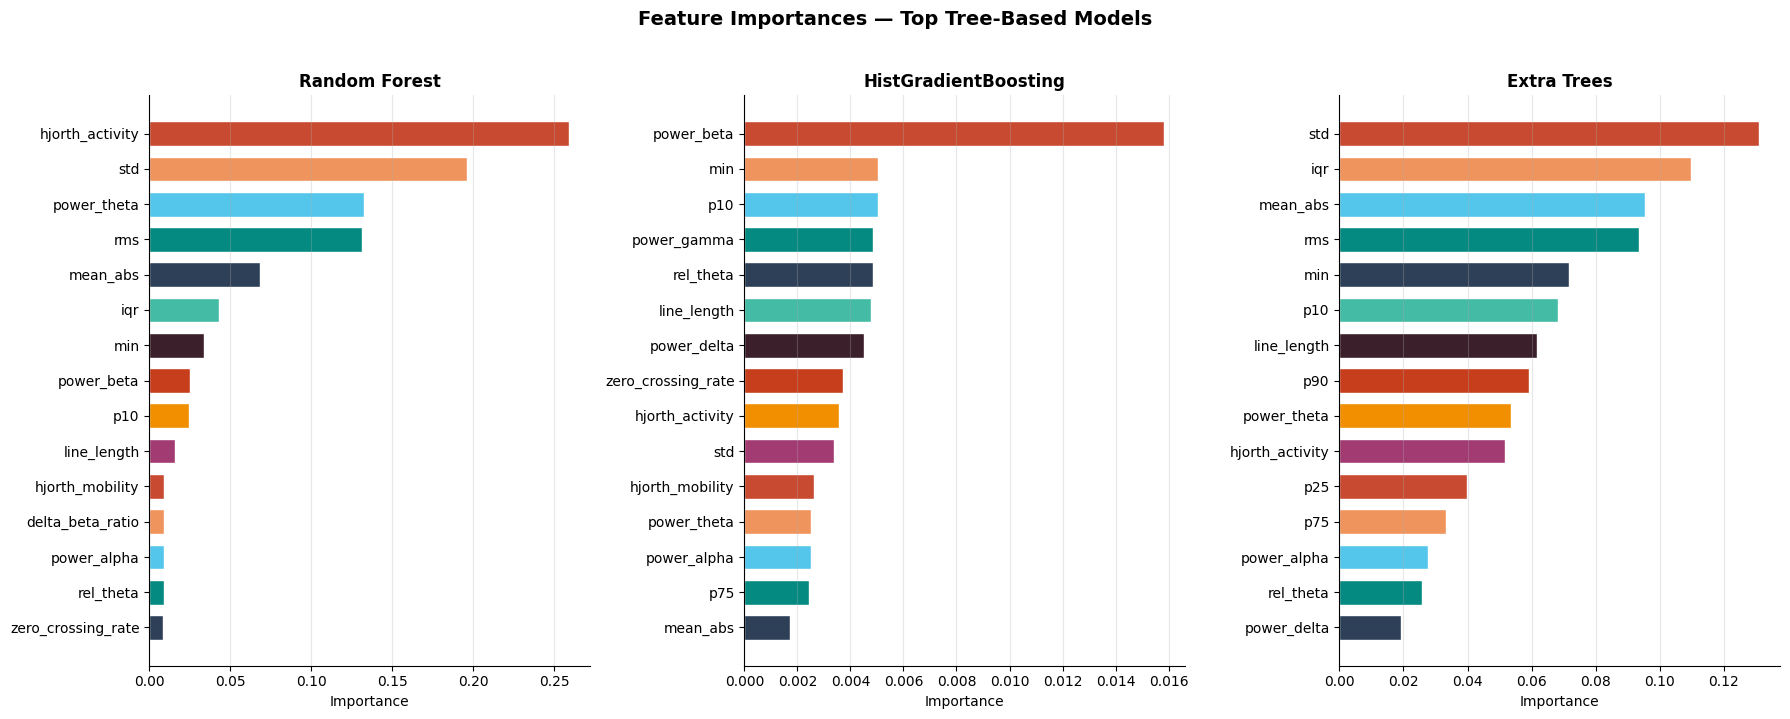

Saved: feature_importances.png


In [40]:
# Figure 7: Feature Importances (top tree-based models)
tree_models = [
    ('Random Forest',       best_rf),
    ('HistGradientBoosting',best_hgb),
    ('Extra Trees',         best_et),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (name, mdl) in zip(axes, tree_models):
    if hasattr(mdl, 'feature_importances_'):
        imp = mdl.feature_importances_
    else:
        result = permutation_importance(mdl, X_test_sel, y_test, n_repeats=5,
                                        random_state=RANDOM_STATE, n_jobs=-1)
        imp = result.importances_mean

    imp_df = (pd.DataFrame({'Feature': CONSENSUS, 'Importance': imp})
              .sort_values('Importance', ascending=True)
              .tail(15))
    colors = [PALETTE[i % len(PALETTE)] for i in range(len(imp_df))]
    ax.barh(imp_df['Feature'], imp_df['Importance'],
            color=colors, edgecolor='white', height=0.7)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance', fontsize=10)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='x', alpha=0.3)

fig.suptitle('Feature Importances — Top Tree-Based Models',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("feature_importances.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_importances.png")

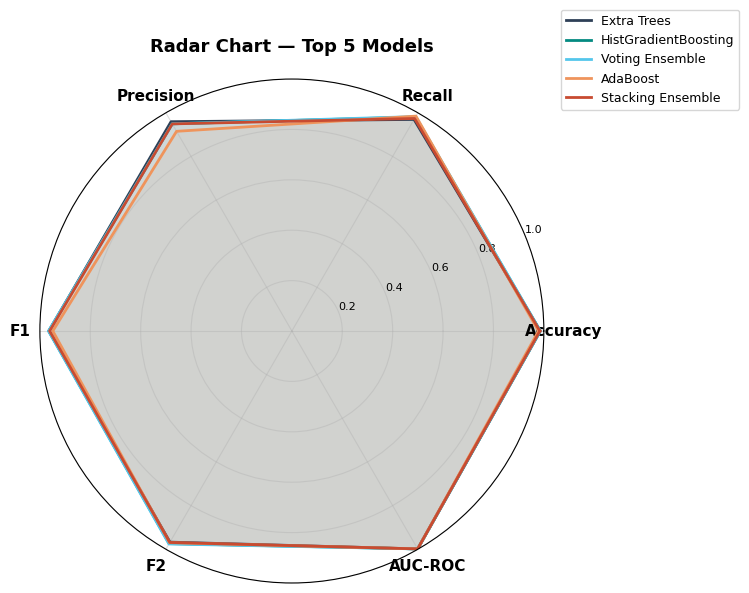

Saved: radar_chart.png


In [41]:
# Figure 8: Radar Chart — Top-5 Models
top5 = results_df.head(5)
rad_metrics = ['Accuracy','Recall','Precision','F1','F2','AUC-ROC']
N       = len(rad_metrics)
angles  = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, (model, row) in enumerate(top5.iterrows()):
    vals  = row[rad_metrics].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color=PALETTE[i], lw=2, label=model)
    ax.fill(angles, vals, color=PALETTE[i], alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(rad_metrics, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'], fontsize=8)
ax.grid(True, alpha=0.4)
ax.set_title('Radar Chart — Top 5 Models', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=9)
plt.tight_layout()
plt.savefig("radar_chart.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: radar_chart.png")

In [42]:
# Figure 9: Classification Reports
print("\n" + "="*65)
print("  DETAILED CLASSIFICATION REPORTS")
print("="*65)

for r in results:
    print(f"\n{'─'*50}")
    print(f"  {r['Model']}")
    print(f"{'─'*50}")
    print(classification_report(y_test, r['_y_pred'],
                                 target_names=['Non-Seizure','Seizure'],
                                 digits=4))


  DETAILED CLASSIFICATION REPORTS

──────────────────────────────────────────────────
  Logistic Regression
──────────────────────────────────────────────────
              precision    recall  f1-score   support

 Non-Seizure     0.9923    0.9777    0.9849      1840
     Seizure     0.9158    0.9696    0.9419       460

    accuracy                         0.9761      2300
   macro avg     0.9540    0.9736    0.9634      2300
weighted avg     0.9770    0.9761    0.9763      2300


──────────────────────────────────────────────────
  Decision Tree
──────────────────────────────────────────────────
              precision    recall  f1-score   support

 Non-Seizure     0.9989    0.9663    0.9823      1840
     Seizure     0.8808    0.9957    0.9347       460

    accuracy                         0.9722      2300
   macro avg     0.9398    0.9810    0.9585      2300
weighted avg     0.9753    0.9722    0.9728      2300


──────────────────────────────────────────────────
  Random Forest

## Non-Tuned Model Performance (Baseline Comparison)

In [43]:
print("=" * 65)
print("  Model Training Without Hyperparameter Tuning")
print("=" * 65)

non_tuned_results = []

models_nt = [
    ("1/11", "Logistic Regression (NT)",
     LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)),
    ("2/11", "Decision Tree (NT)",
     DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ("3/11", "Random Forest (NT)",
     RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
    ("4/11", "Gradient Boosting (NT)",
     GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ("5/11", "HistGradientBoosting (NT)",
     HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ("6/11", "Extra Trees (NT)",
     ExtraTreesClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
    ("7/11", "AdaBoost (NT)",
     AdaBoostClassifier(random_state=RANDOM_STATE)),
    ("8/11", "K-Nearest Neighbors (NT)",
     KNeighborsClassifier(n_jobs=-1)),
    ("9/11", "SVC (NT)",
     SVC(probability=True, class_weight='balanced', random_state=RANDOM_STATE)),
]

for num, name, model_nt in models_nt:
    print(f"\n[{num}] {name}")
    non_tuned_results.append(evaluate_model(name, model_nt, X_bal, y_bal, X_test_sel, y_test))

# Voting Ensemble (non-tuned)
lr_nt, dt_nt, rf_nt, gb_nt, hgb_nt, et_nt, ada_nt, knn_nt, svc_nt = [
    r['_model'] for r in non_tuned_results
]

print("\n[10/11] Voting Ensemble (NT, soft)")
voting_nt = VotingClassifier(
    estimators=[('lr', lr_nt), ('rf', rf_nt), ('gb', gb_nt),
                ('hgb', hgb_nt), ('et', et_nt)],
    voting='soft', n_jobs=-1
)
non_tuned_results.append(evaluate_model('Voting Ensemble (NT)', voting_nt,
                                         X_bal, y_bal, X_test_sel, y_test))

print("\n[11/11] Stacking Ensemble (NT)")
stacking_nt = StackingClassifier(
    estimators=[('rf', rf_nt), ('gb', gb_nt), ('hgb', hgb_nt)],
    final_estimator=LogisticRegression(max_iter=1000, C=1,
                                       class_weight='balanced',
                                       random_state=RANDOM_STATE),
    cv=StratifiedKFold(3), passthrough=False, n_jobs=-1
)
non_tuned_results.append(evaluate_model('Stacking Ensemble (NT)', stacking_nt,
                                         X_bal, y_bal, X_test_sel, y_test))

print("\n✓ All non-tuned models trained and evaluated.")

  Model Training Without Hyperparameter Tuning

[1/11] Logistic Regression (NT)
  Logistic Regression (NT)       AUC=0.9957  F1=0.9396  Recall=0.9630

[2/11] Decision Tree (NT)
  Decision Tree (NT)             AUC=0.9617  F1=0.9352  Recall=0.9413

[3/11] Random Forest (NT)
  Random Forest (NT)             AUC=0.9980  F1=0.9595  Recall=0.9783

[4/11] Gradient Boosting (NT)
  Gradient Boosting (NT)         AUC=0.9980  F1=0.9514  Recall=0.9783

[5/11] HistGradientBoosting (NT)
  HistGradientBoosting (NT)      AUC=0.9984  F1=0.9638  Recall=0.9826

[6/11] Extra Trees (NT)
  Extra Trees (NT)               AUC=0.9986  F1=0.9646  Recall=0.9761

[7/11] AdaBoost (NT)
  AdaBoost (NT)                  AUC=0.9974  F1=0.9380  Recall=0.9870

[8/11] K-Nearest Neighbors (NT)
  K-Nearest Neighbors (NT)       AUC=0.9899  F1=0.9495  Recall=0.9804

[9/11] SVC (NT)
  SVC (NT)                       AUC=0.9959  F1=0.9432  Recall=0.9739

[10/11] Voting Ensemble (NT, soft)
  Voting Ensemble (NT)           AUC=0

In [44]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
import pandas as pd

val_rows = []
for r in results:
    m = r['_model']  # the fitted tuned model
    vp = m.predict_proba(X_val_sel)[:, 1]   # seizure probability on validation set
    vy = m.predict(X_val_sel)
    val_rows.append({
        'Model'     : r['Model'],
        'Val_AUC'   : roc_auc_score(y_val, vp),
        'Val_F1'    : f1_score(y_val, vy),
        'Val_Recall': recall_score(y_val, vy),
        'Val_Prec'  : precision_score(y_val, vy, zero_division=0)
    })

val_df = pd.DataFrame(val_rows).sort_values('Val_AUC', ascending=False).reset_index(drop=True)
print("VALIDATION SET RANKING (1,150 samples: 230 seizure / 920 non-seizure)")
print(val_df.round(4).to_string(index=False))
print(f"\nTest-set winner was: {results_df.index[0]}")

VALIDATION SET RANKING (1,150 samples: 230 seizure / 920 non-seizure)
               Model  Val_AUC  Val_F1  Val_Recall  Val_Prec
       Random Forest   0.9988  0.9675      0.9696    0.9654
   Stacking Ensemble   0.9987  0.9696      0.9696    0.9696
         Extra Trees   0.9986  0.9675      0.9696    0.9654
   Gradient Boosting   0.9986  0.9654      0.9696    0.9612
HistGradientBoosting   0.9986  0.9675      0.9696    0.9654
     Voting Ensemble   0.9986  0.9654      0.9696    0.9612
            AdaBoost   0.9984  0.9471      0.9739    0.9218
                 SVC   0.9979  0.9569      0.9652    0.9487
 K-Nearest Neighbors   0.9962  0.9512      0.9739    0.9295
 Logistic Regression   0.9959  0.9266      0.9609    0.8947
       Decision Tree   0.9928  0.9246      0.9870    0.8697

Test-set winner was: Extra Trees


In [45]:
non_tuned_results_df = (pd.DataFrame(non_tuned_results)[metric_cols]
                        .set_index('Model')
                        .sort_values('AUC-ROC', ascending=False))

print("\n" + "="*65)
print("  NON-TUNED MODEL LEADERBOARD")
print("="*65)
print(non_tuned_results_df.round(4).to_string())


  NON-TUNED MODEL LEADERBOARD
                           Accuracy  Recall  Precision      F1      F2  AUC-ROC
Model                                                                          
Extra Trees (NT)             0.9857  0.9761     0.9533  0.9646  0.9714   0.9986
Voting Ensemble (NT)         0.9848  0.9848     0.9418  0.9628  0.9759   0.9984
HistGradientBoosting (NT)    0.9852  0.9826     0.9456  0.9638  0.9750   0.9984
Stacking Ensemble (NT)       0.9843  0.9739     0.9492  0.9614  0.9689   0.9982
Random Forest (NT)           0.9835  0.9783     0.9414  0.9595  0.9707   0.9980
Gradient Boosting (NT)       0.9800  0.9783     0.9259  0.9514  0.9673   0.9980
AdaBoost (NT)                0.9739  0.9870     0.8937  0.9380  0.9668   0.9974
SVC (NT)                     0.9765  0.9739     0.9143  0.9432  0.9614   0.9959
Logistic Regression (NT)     0.9752  0.9630     0.9172  0.9396  0.9535   0.9957
K-Nearest Neighbors (NT)     0.9791  0.9804     0.9204  0.9495  0.9678   0.9899
Decision 

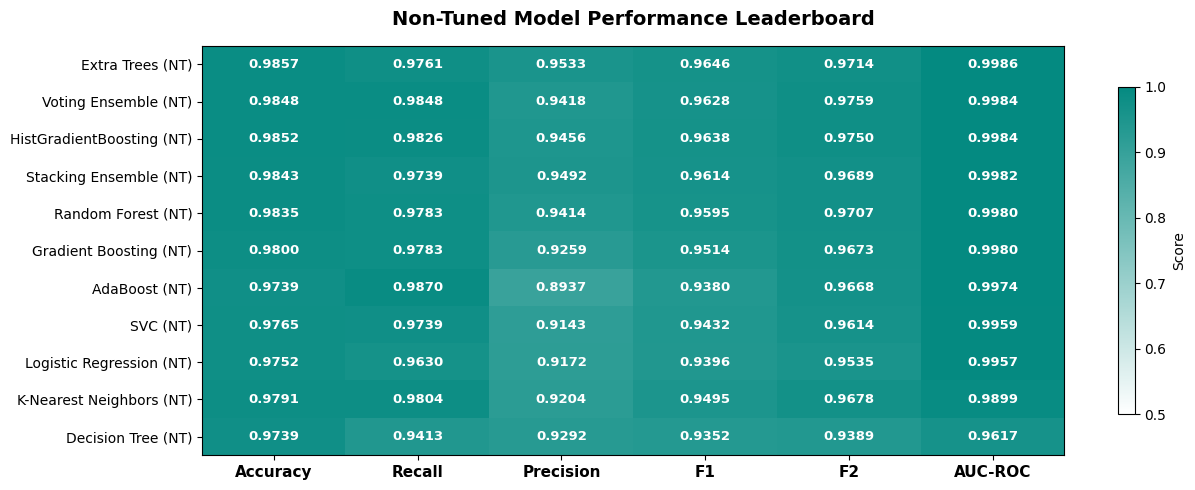

Saved: leaderboard_heatmap_nontuned.png


In [46]:
# Non-tuned Leaderboard Heatmap
fig, ax = plt.subplots(figsize=(13, 5))
data_mat_nt = non_tuned_results_df.values.astype(float)
cmap_nt = LinearSegmentedColormap.from_list('teal', ['#ffffff','#048A81'])
im_nt   = ax.imshow(data_mat_nt, cmap=cmap_nt, aspect='auto', vmin=0.5, vmax=1.0)
ax.set_xticks(range(len(non_tuned_results_df.columns)))
ax.set_xticklabels(non_tuned_results_df.columns, fontsize=11, fontweight='bold')
ax.set_yticks(range(len(non_tuned_results_df.index)))
ax.set_yticklabels(non_tuned_results_df.index, fontsize=10)
for i in range(len(non_tuned_results_df.index)):
    for j in range(len(non_tuned_results_df.columns)):
        v   = data_mat_nt[i, j]
        col = 'white' if v > 0.77 else '#1a1a2e'
        ax.text(j, i, f'{v:.4f}', ha='center', va='center',
                fontsize=9.5, color=col, fontweight='bold')
plt.colorbar(im_nt, ax=ax, shrink=0.8, label='Score')
ax.set_title('Non-Tuned Model Performance Leaderboard', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig("leaderboard_heatmap_nontuned.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: leaderboard_heatmap_nontuned.png")

## Learning Curve for the Best Model

Generating learning curve for: Extra Trees


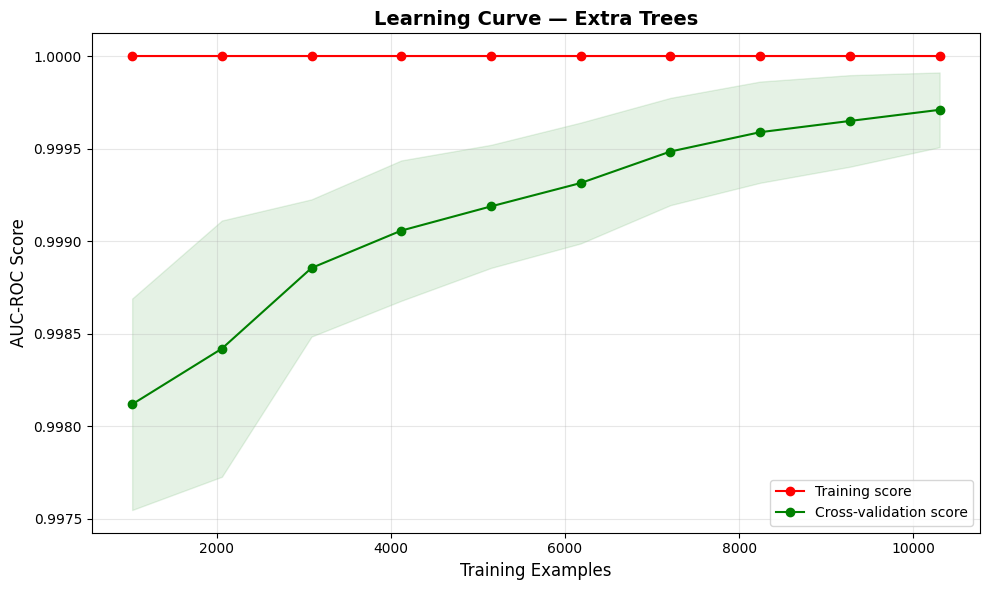

Saved: learning_curve.png


In [47]:
best_model_name = results_df.index[0]
best_model_obj  = next(r['_model'] for r in results if r['Model'] == best_model_name)

print(f"Generating learning curve for: {best_model_name}")
train_sizes, train_scores, test_scores = learning_curve(
    estimator   = best_model_obj,
    X           = X_bal,
    y           = y_bal,
    cv          = cv,
    n_jobs      = -1,
    train_sizes = np.linspace(0.1, 1.0, 10),
    scoring     = 'roc_auc'
)

tr_mean = np.mean(train_scores, axis=1)
tr_std  = np.std(train_scores, axis=1)
cv_mean = np.mean(test_scores, axis=1)
cv_std  = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.fill_between(train_sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.1, color='r')
plt.fill_between(train_sizes, cv_mean - cv_std, cv_mean + cv_std, alpha=0.1, color='g')
plt.plot(train_sizes, tr_mean, 'o-', color='r', label='Training score')
plt.plot(train_sizes, cv_mean, 'o-', color='g', label='Cross-validation score')
plt.title(f'Learning Curve — {best_model_name}', fontsize=14, fontweight='bold')
plt.xlabel('Training Examples', fontsize=12)
plt.ylabel('AUC-ROC Score', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: learning_curve.png")

## Feature Correlation Heatmaps

### Learning Curves for All Models

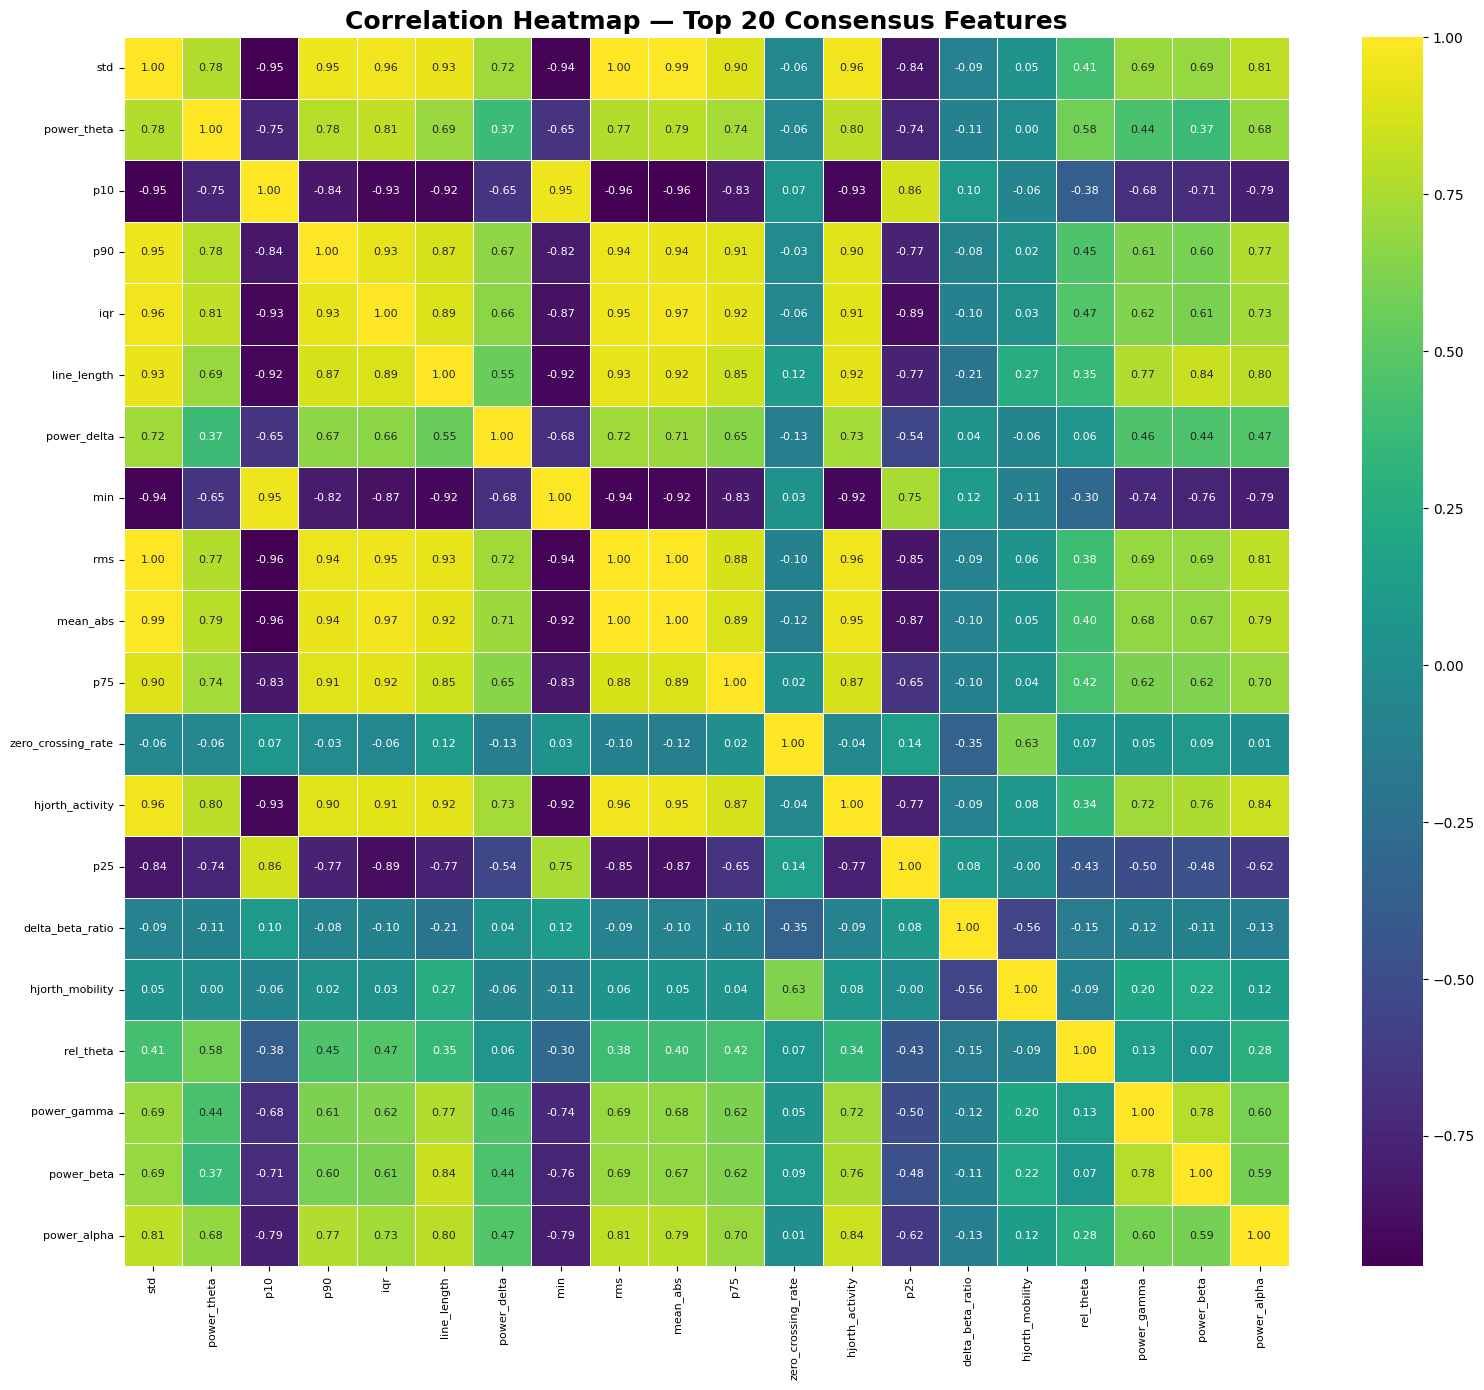

Saved: feature_correlation_heatmap_top20.png


In [48]:
# Top-20 consensus features correlation heatmap
top_20_features = CONSENSUS[:20]
top_20_indices  = [feature_names_all.index(f) for f in top_20_features]

corr_df_top20     = pd.DataFrame(X_combined[:, top_20_indices], columns=top_20_features)
corr_matrix_top20 = corr_df_top20.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix_top20, annot=True, cmap='viridis', fmt=".2f",
            linewidths=.5, annot_kws={"size": 8})
plt.title('Correlation Heatmap — Top 20 Consensus Features', fontsize=18, fontweight='bold')
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8, rotation=0)
plt.tight_layout()
plt.savefig("feature_correlation_heatmap_top20.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_correlation_heatmap_top20.png")

## Step 9 · SHAP Explainability

SHAP (SHapley Additive exPlanations) for the best Extra Trees model.

In [49]:
explainer = shap.TreeExplainer(best_et)
shap_values = explainer.shap_values(X_test_sel)

sv = shap_values[:, :, 1]  # ← KEY DIFFERENCE
print(f"SHAP values shape: {sv.shape}")

SHAP values shape: (2300, 20)


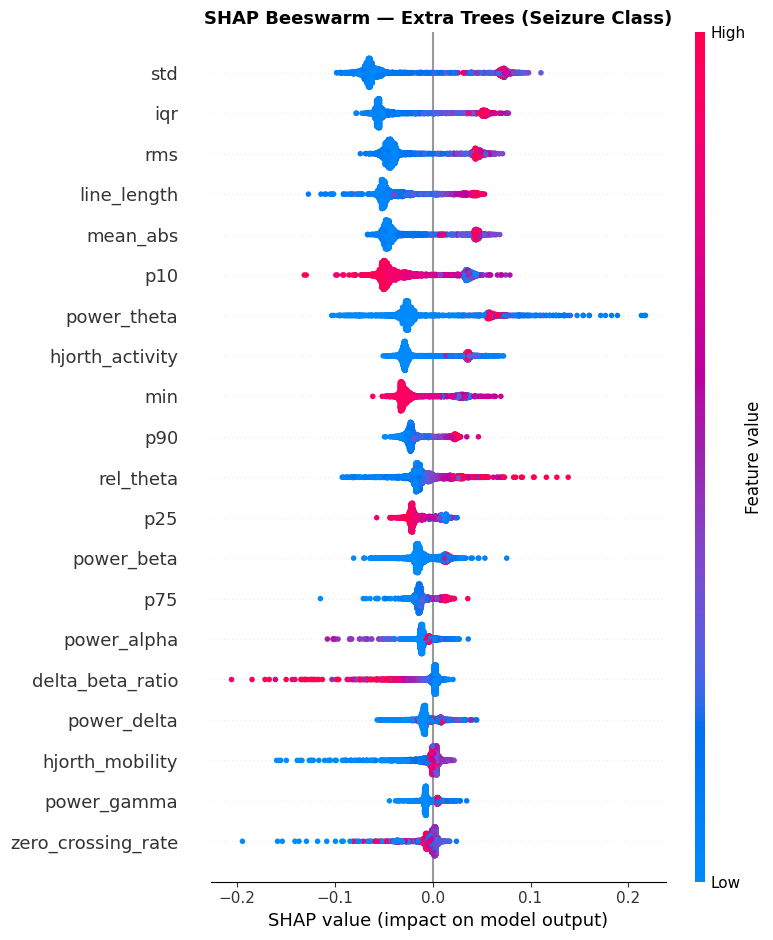

Saved: shap_beeswarm.png


In [50]:
# SHAP Summary (beeswarm) plot
plt.figure(figsize=(10, 8))
shap.summary_plot(sv, X_test_sel, feature_names=CONSENSUS, show=False)
plt.title('SHAP Beeswarm — Extra Trees (Seizure Class)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_beeswarm.png")

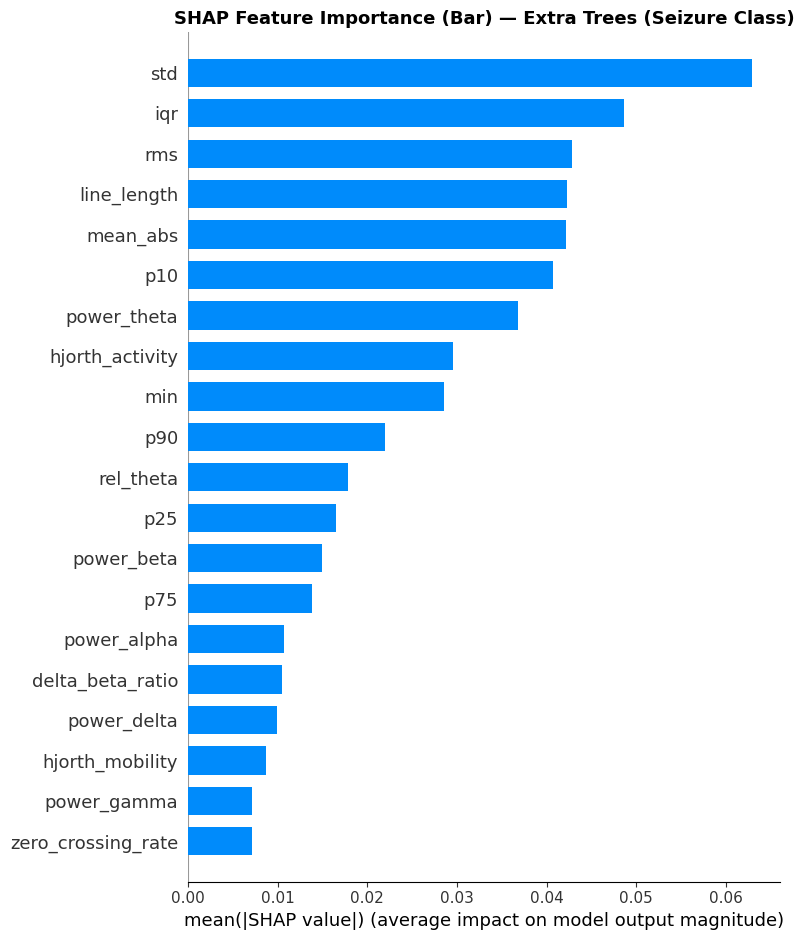

Saved: shap_summary_bar.png


In [51]:
# SHAP Summary (bar) plot
plt.figure(figsize=(10, 6))
shap.summary_plot(sv, X_test_sel, feature_names=CONSENSUS, plot_type="bar", show=False)
plt.title('SHAP Feature Importance (Bar) — Extra Trees (Seizure Class)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("shap_summary_bar.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_summary_bar.png")

### Combined SHAP Dependence Plot for Top 4 Features

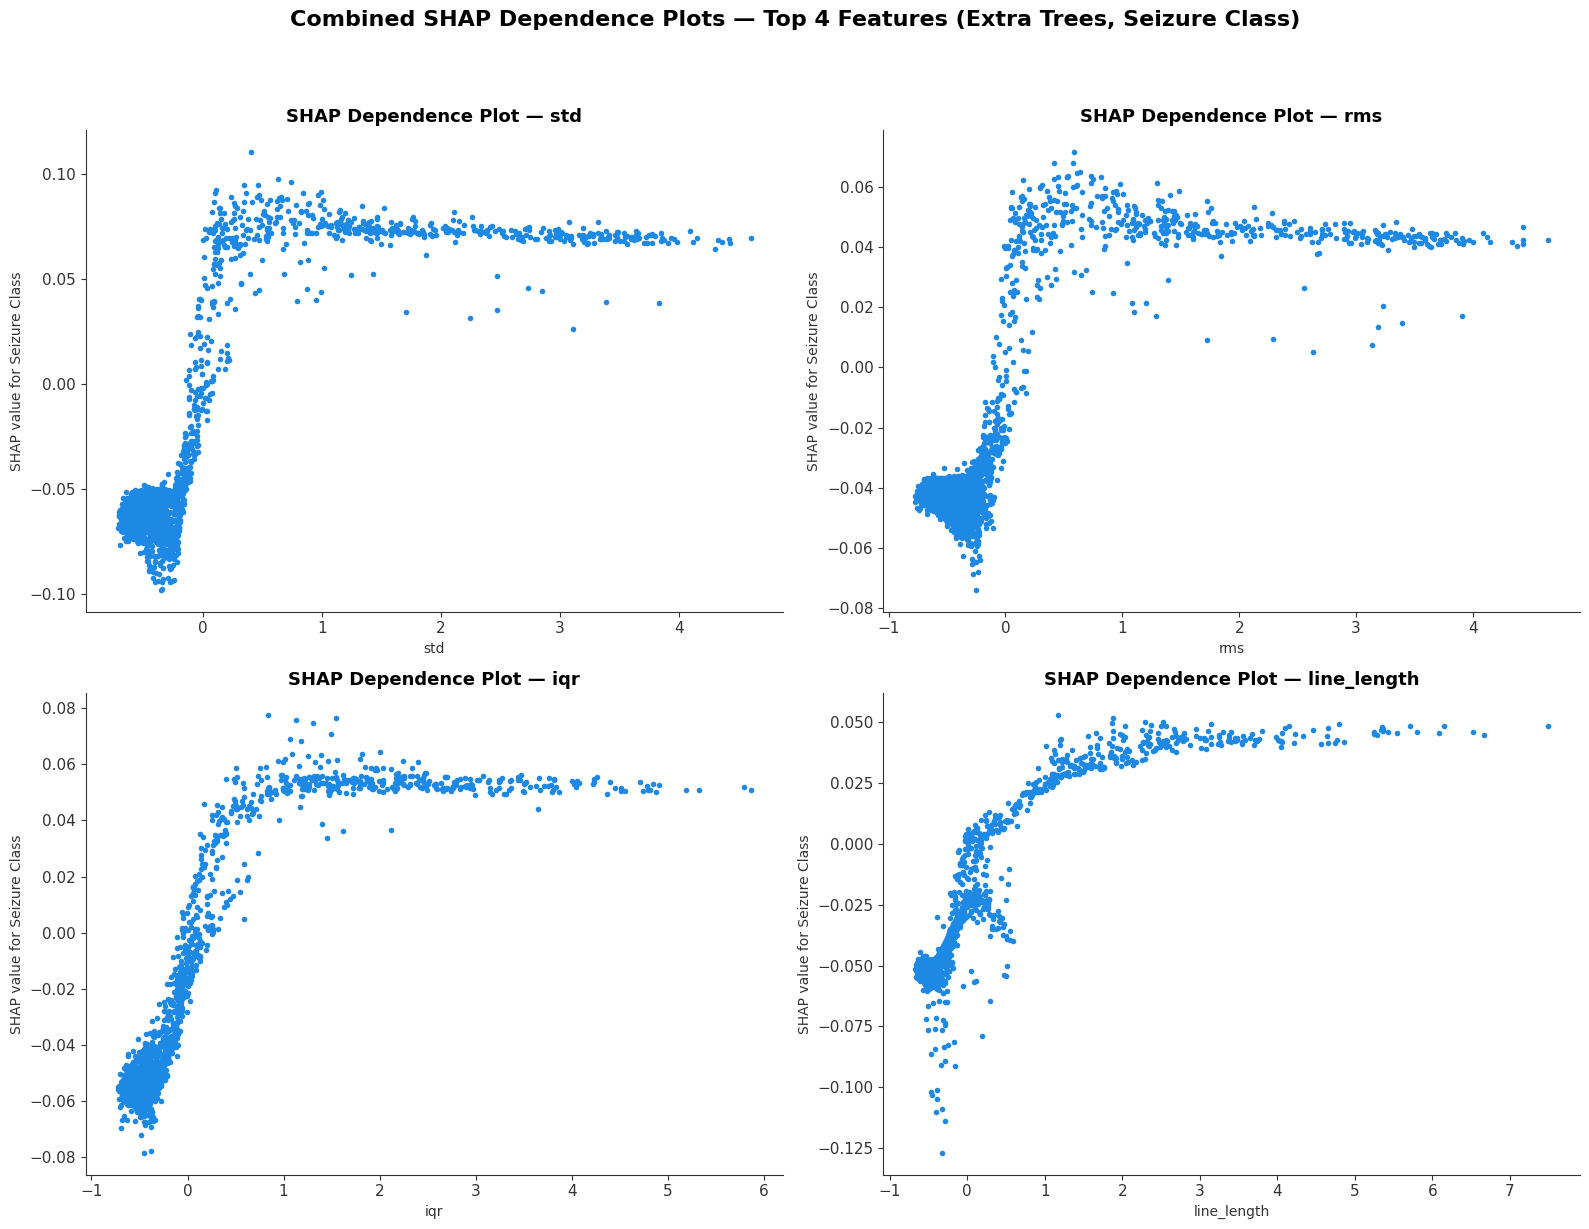

Saved: shap_dependence_top4_combined.png


In [52]:
import matplotlib.pyplot as plt

top_4_features = ['std', 'rms', 'iqr', 'line_length']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, feature_name in enumerate(top_4_features):
    ax = axes[i]
    if feature_name in CONSENSUS:
        feat_idx_shap = CONSENSUS.index(feature_name)

        # Use shap.dependence_plot directly with the ax argument
        shap.dependence_plot(feat_idx_shap, sv, X_test_sel,
                             feature_names=CONSENSUS, show=False,
                             interaction_index=None, ax=ax)
        ax.set_title(f'SHAP Dependence Plot — {feature_name}',
                     fontsize=13, fontweight='bold')
        ax.set_xlabel(feature_name, fontsize=10)
        ax.set_ylabel('SHAP value for Seizure Class', fontsize=10)

    else:
        ax.set_title(f'{feature_name} not found in consensus features', fontsize=12)
        ax.axis('off') # Hide axis if feature not found

plt.suptitle('Combined SHAP Dependence Plots — Top 4 Features (Extra Trees, Seizure Class)',
             y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98]) # Adjust layout to prevent suptitle overlap
plt.savefig("shap_dependence_top4_combined.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: shap_dependence_top4_combined.png")

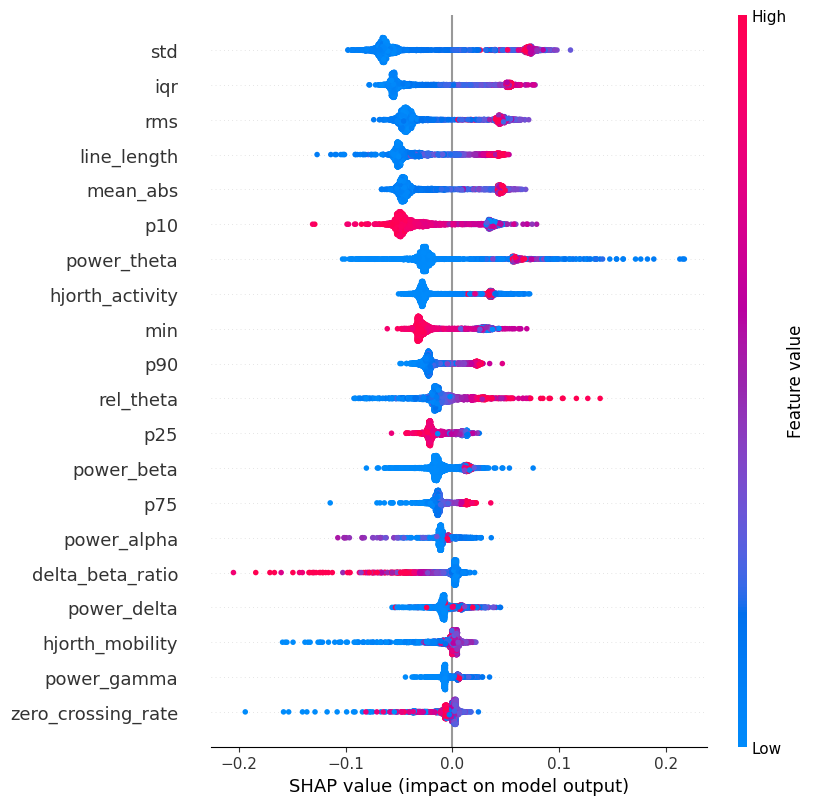

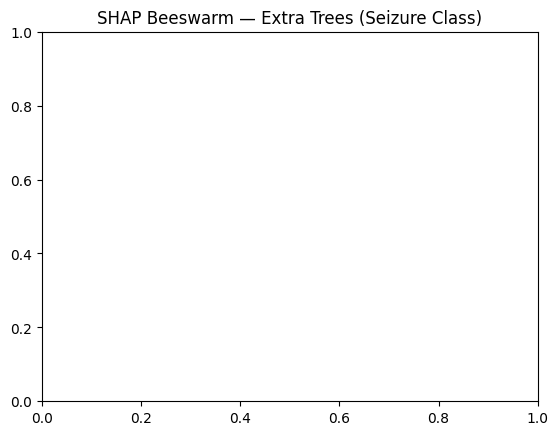

Shape of values passed to beeswarm: (2300, 20)


In [53]:
import shap
import matplotlib.pyplot as plt

# Your SHAP values (already computed and stored in 'sv' for the seizure class)
# 'sv' is a 3D array (n_samples, n_features, n_classes)

# Re-initialize the SHAP TreeExplainer to correctly access expected_value
# This ensures we use the shap.TreeExplainer context for SHAP plots
temp_shap_explainer = shap.TreeExplainer(best_et)

# Create a shap.Explanation object required by shap.plots.beeswarm
# We use the 'sv' variable for the values, but slice it to get the 2D array for class 1 (seizure)
shap_explanation_seizure = shap.Explanation(
    values=sv, # Corrected: sv is already 2D for class 1
    base_values=temp_shap_explainer.expected_value[1], # Take expected value for class 1
    data=X_test_sel,
    feature_names=CONSENSUS
)

# Plot using the Explanation object
shap.plots.beeswarm(shap_explanation_seizure, max_display=20)
plt.title('SHAP Beeswarm — Extra Trees (Seizure Class)')
plt.show()
print(f"Shape of values passed to beeswarm: {sv.shape}") # Should show (2300, 20)

## Step 9b · LIME Explainability (Local Explanations)

LIME (Local Interpretable Model-agnostic Explanations) provides local explanations for individual predictions.

In [54]:
# Install LIME if not already installed
import subprocess
import sys

try:
    import lime
    print("LIME is already installed.")
except ImportError:
    print("Installing LIME...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lime", "-q"])
    import lime
    print("LIME installed successfully.")

LIME is already installed.


In [55]:
import lime
import lime.lime_tabular

# Select the best model (Extra Trees in this case)
best_model_lime = best_et

# Choose an instance from the test set to explain
# Find an instance that was predicted as 'Seizure' (label 1)
instance_idx = -1
for i, pred_label in enumerate(results[0]['_y_pred']):
    if pred_label == 1:
        instance_idx = i
        break

if instance_idx == -1:
    print("Could not find an instance predicted as 'Seizure'. Explaining the default instance (index 50).")
    instance_idx = 50 # Fallback if no seizure prediction is found

instance_to_explain = X_test_sel[instance_idx]
true_label = y_test[instance_idx]
predicted_label = best_model_lime.predict(instance_to_explain.reshape(1, -1))[0]
predicted_proba = best_model_lime.predict_proba(instance_to_explain.reshape(1, -1))[0]

print(f"Explaining instance at index {instance_idx}:")
print(f"  True label: {true_label} (Seizure)" if true_label == 1 else f"  True label: {true_label} (Non-Seizure)")
print(f"  Predicted label: {predicted_label} (Seizure)" if predicted_label == 1 else f"  Predicted label: {predicted_label} (Non-Seizure)")
print(f"  Predicted probabilities: {predicted_proba}")

Explaining instance at index 10:
  True label: 1 (Seizure)
  Predicted label: 1 (Seizure)
  Predicted probabilities: [0.00333333 0.99666667]



LIME Explanation for the instance (Top 20 Features, focusing on Seizure class):


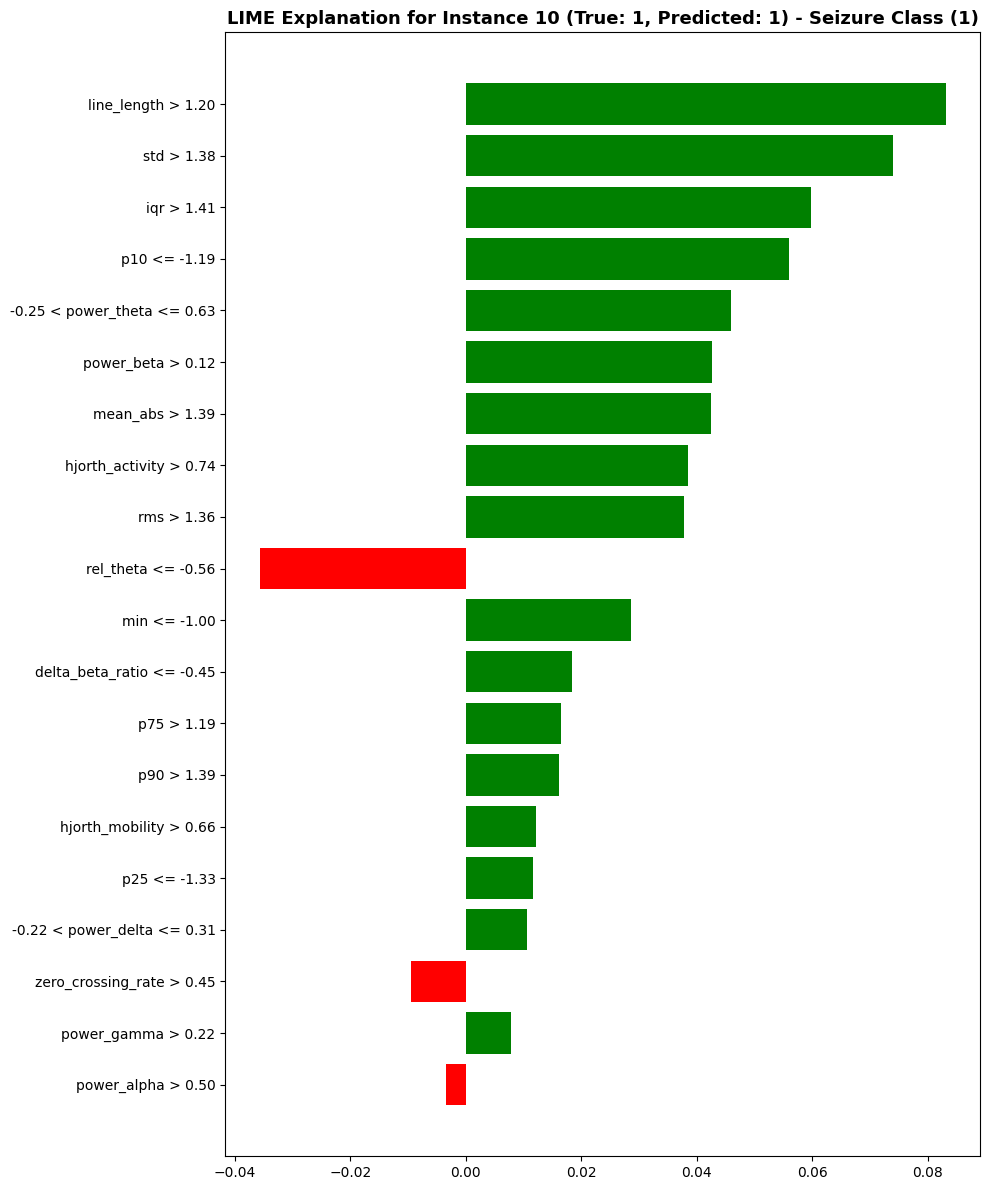

Saved: lime_explanation_instance_10_20features_seizure_class.png


In [56]:
import matplotlib.pyplot as plt

# Create a LIME Tabular Explainer
# feature_names should be the names of the features used in X_test_sel (which is CONSENSUS)
# class_names are the target classes (0: Non-Seizure, 1: Seizure)
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_bal,  # Use balanced training data for explainer
    feature_names=CONSENSUS,
    class_names=['Non-Seizure', 'Seizure'],
    mode='classification'
)

# Generate explanation for the chosen instance
# num_features=20
explanation = explainer.explain_instance(
    data_row=instance_to_explain,
    predict_fn=best_model_lime.predict_proba,
    num_features=20,
    labels=[1]  # <--- Explicitly request explanation for the 'Seizure' class (label 1)
)

print("\nLIME Explanation for the instance (Top 20 Features, focusing on Seizure class):")
# Display the explanation as a matplotlib figure with a white background
fig = explanation.as_pyplot_figure(label=1) # <--- Pass label to as_pyplot_figure
fig.patch.set_facecolor('white')  # Set figure background to white

# Adjust figure size to fit 20 features (taller)
fig.set_size_inches(10, 12)  #

plt.title(f'LIME Explanation for Instance {instance_idx} (True: {true_label}, Predicted: {predicted_label}) - Seizure Class (1)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f"lime_explanation_instance_{instance_idx}_20features_seizure_class.png",  # <--- UPDATED filename
            dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print(f"Saved: lime_explanation_instance_{instance_idx}_20features_seizure_class.png")

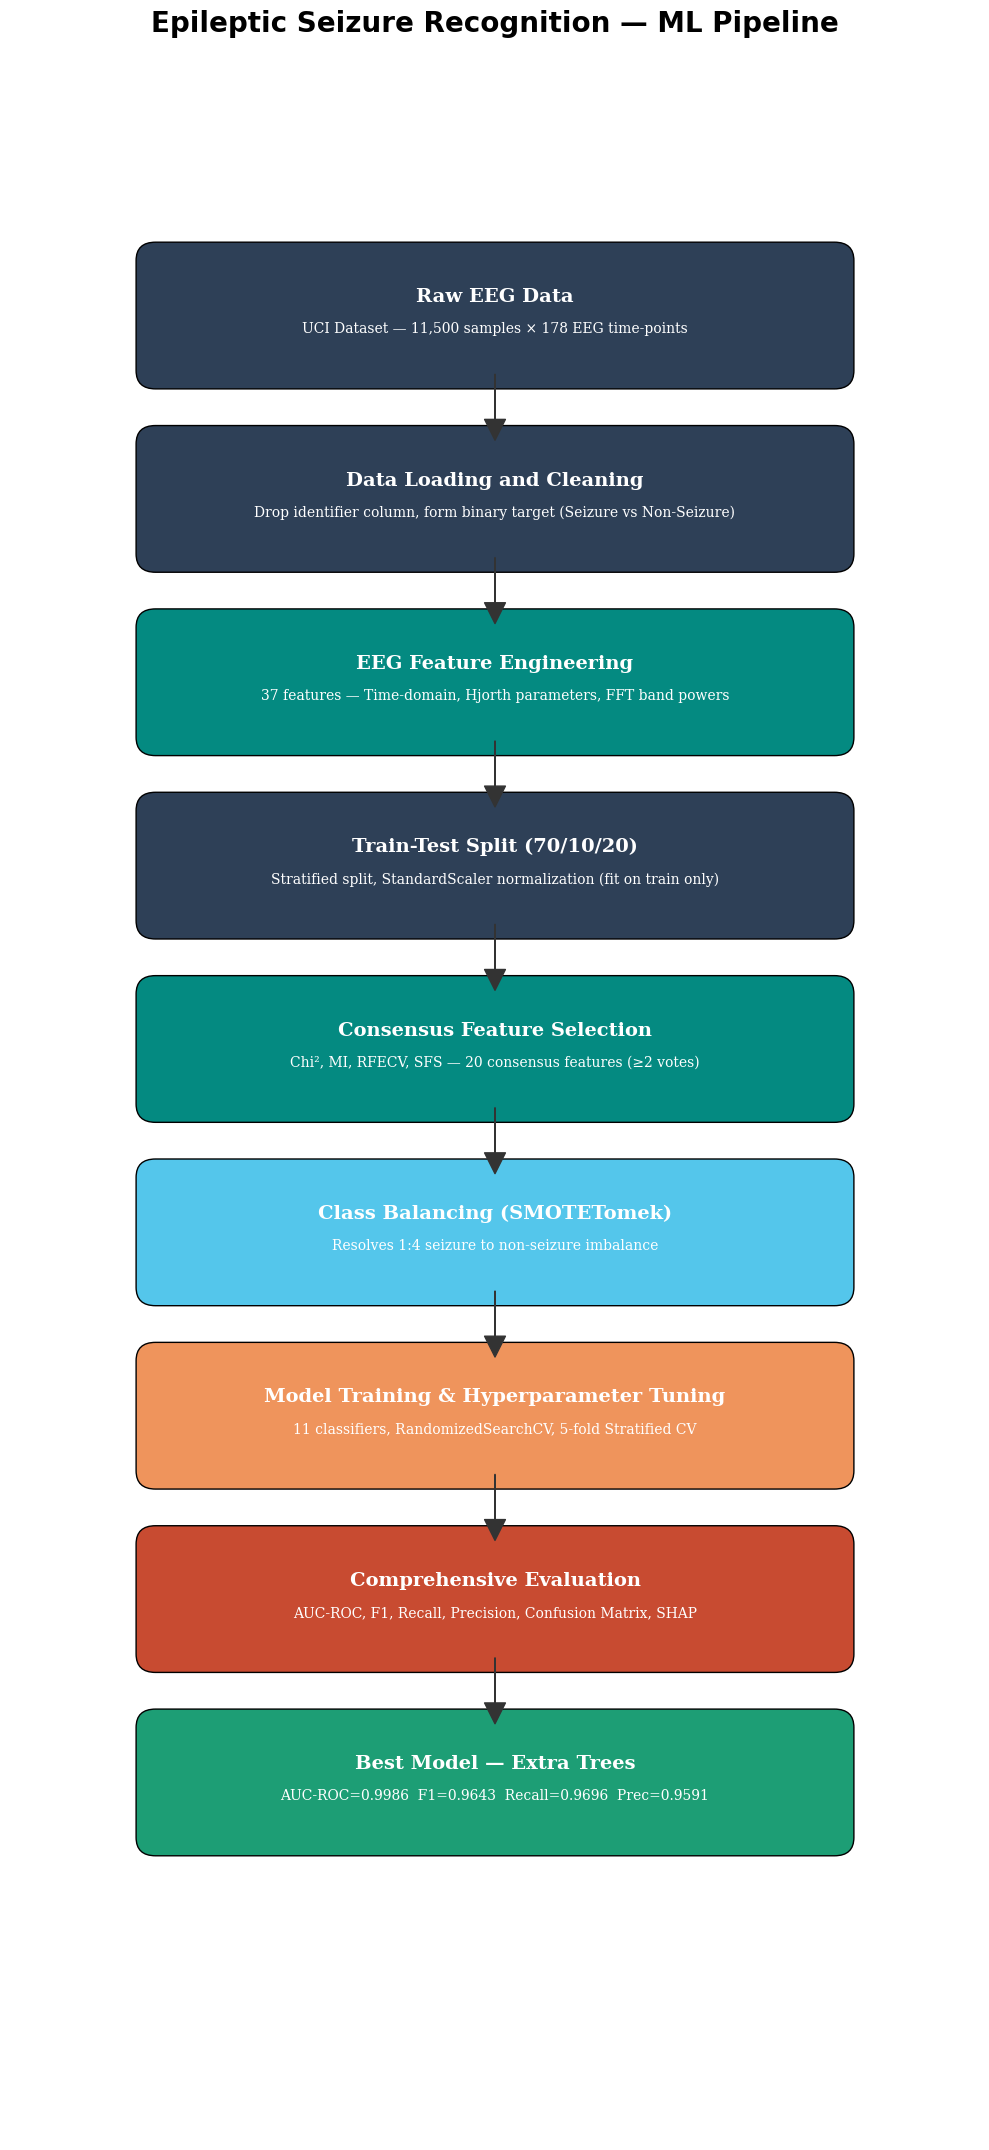

Saved: pipeline_flowchart.png


In [57]:
import matplotlib.patches as patches
from matplotlib.font_manager import FontProperties

def create_publication_flowchart(filename="pipeline_flowchart.png"):
    fig, ax = plt.subplots(figsize=(10, 22), facecolor='white')
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 22)
    ax.axis('off')

    box_width  = 7.0
    box_height = 1.2
    v_spacing  = 0.8

    fp_title = FontProperties(family='serif', weight='bold', size=14)
    fp_sub   = FontProperties(family='serif', size=10)

    color_navy  = '#2E4057'
    color_teal  = '#048A81'
    color_cyan  = '#54C6EB'
    color_orange= '#EF945C'
    color_coral = '#C84B31'
    color_dkgrn = '#1D9E75'

    best_name = results_df.index[0]
    best_auc  = results_df.loc[best_name, 'AUC-ROC']
    best_f1   = results_df.loc[best_name, 'F1']
    best_rec  = results_df.loc[best_name, 'Recall']
    best_pre  = results_df.loc[best_name, 'Precision']

    nodes = [
        {"title": "Raw EEG Data",
         "subtitle": f"UCI Dataset — 11,500 samples × 178 EEG time-points",
         "color": color_navy},
        {"title": "Data Loading and Cleaning",
         "subtitle": "Drop identifier column, form binary target (Seizure vs Non-Seizure)",
         "color": color_navy},
        {"title": "EEG Feature Engineering",
         "subtitle": f"37 features — Time-domain, Hjorth parameters, FFT band powers",
         "color": color_teal},
        {"title": "Train-Test Split (70/10/20)",
         "subtitle": "Stratified split, StandardScaler normalization (fit on train only)",
         "color": color_navy},
        {"title": "Consensus Feature Selection",
         "subtitle": f"Chi², MI, RFECV, SFS — {len(CONSENSUS)} consensus features (≥2 votes)",
         "color": color_teal},
        {"title": "Class Balancing (SMOTETomek)",
         "subtitle": "Resolves 1:4 seizure to non-seizure imbalance",
         "color": color_cyan},
        {"title": "Model Training & Hyperparameter Tuning",
         "subtitle": "11 classifiers, RandomizedSearchCV, 5-fold Stratified CV",
         "color": color_orange},
        {"title": "Comprehensive Evaluation",
         "subtitle": "AUC-ROC, F1, Recall, Precision, Confusion Matrix, SHAP",
         "color": color_coral},
        {"title": f"Best Model — {best_name}",
         "subtitle": f"AUC-ROC={best_auc:.4f}  F1={best_f1:.4f}  Recall={best_rec:.4f}  Prec={best_pre:.4f}",
         "color": color_dkgrn},
    ]

    node_coords = {}
    fig.suptitle('Epileptic Seizure Recognition — ML Pipeline',
                 fontsize=20, fontweight='bold', y=0.975)

    cur_y_bot = ax.get_ylim()[1] - 1.5
    for node in nodes:
        cy = cur_y_bot - box_height / 2
        node_coords[node["title"]] = (5.0, cy)
        rect = patches.FancyBboxPatch(
            (5.0 - box_width/2, cy - box_height/2),
            box_width, box_height,
            boxstyle=patches.BoxStyle("Round", pad=0.2, rounding_size=0.2),
            facecolor=node["color"], edgecolor='black', lw=1
        )
        ax.add_patch(rect)
        ax.text(5.0, cy+0.2,  node["title"],    fontproperties=fp_title, color='white', ha='center', va='center')
        ax.text(5.0, cy-0.15, node["subtitle"], fontproperties=fp_sub,   color='white', ha='center', va='center')
        cur_y_bot -= (box_height + v_spacing)

    for i in range(len(nodes) - 1):
        sx, sy = node_coords[nodes[i  ]["title"]]
        ex, ey = node_coords[nodes[i+1]["title"]]
        ax.annotate("",
            xy=(ex, ey + box_height/2), xytext=(sx, sy - box_height/2),
            arrowprops=dict(facecolor='#333333', edgecolor='#333333',
                            shrink=0.05, width=0.005, headwidth=15, headlength=15))

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {filename}")

create_publication_flowchart()

## Step 10 · Pipeline Summary

In [58]:
best_model = results_df.index[0]
best_auc   = results_df.loc[best_model, 'AUC-ROC']
best_f1    = results_df.loc[best_model, 'F1']
best_rec   = results_df.loc[best_model, 'Recall']
best_pre   = results_df.loc[best_model, 'Precision']

print("""
╔══════════════════════════════════════════════════════════════╗
║              EPILEPTIC SEIZURE PIPELINE SUMMARY              ║
╠══════════════════════════════════════════════════════════════╣""")
print(f"║  Dataset          : 11,500 samples × 178 EEG time-points   ║")
print(f"║  Task             : Binary — Seizure vs Non-Seizure         ║")
print(f"║  Raw features     : 178 (EEG time-points X1–X178)          ║")
print(f"║  Engineered feats : {len(feature_names_eng)} (FFT, Hjorth, stats, band power)  ║")
print(f"║  Consensus feats  : {len(CONSENSUS):<4} (selected by ≥2 methods)             ║")
print(f"║  Models trained   : 11 (tuned) + 11 (non-tuned)            ║")
print(f"║  Balancing        : SMOTETomek                              ║")
print(f"║  Tuning           : RandomizedSearchCV (5-fold StratKFold) ║")
print("╠══════════════════════════════════════════════════════════════╣")
print(f"║  🏆 BEST MODEL    : {best_model:<40}║")
print(f"║     AUC-ROC       : {best_auc:.4f}                                   ║")
print(f"║     F1-Score      : {best_f1:.4f}                                   ║")
print(f"║     Recall        : {best_rec:.4f}                                   ║")
print(f"║     Precision     : {best_pre:.4f}                                   ║")
print("╠══════════════════════════════════════════════════════════════╣")
print("║  Saved plots: leaderboard_heatmap, roc_curves,             ║")
print("║  confusion_matrices, pr_curves, radar_chart,               ║")
print("║  feature_importances, shap_beeswarm, shap_summary_bar,     ║")
print("║  learning_curve, feature_correlation_heatmap, flowchart    ║")
print("╚══════════════════════════════════════════════════════════════╝")

print("\n  Full Leaderboard (sorted by AUC-ROC):")
print(results_df.round(4).to_string())


╔══════════════════════════════════════════════════════════════╗
║              EPILEPTIC SEIZURE PIPELINE SUMMARY              ║
╠══════════════════════════════════════════════════════════════╣
║  Dataset          : 11,500 samples × 178 EEG time-points   ║
║  Task             : Binary — Seizure vs Non-Seizure         ║
║  Raw features     : 178 (EEG time-points X1–X178)          ║
║  Engineered feats : 37 (FFT, Hjorth, stats, band power)  ║
║  Consensus feats  : 20   (selected by ≥2 methods)             ║
║  Models trained   : 11 (tuned) + 11 (non-tuned)            ║
║  Balancing        : SMOTETomek                              ║
║  Tuning           : RandomizedSearchCV (5-fold StratKFold) ║
╠══════════════════════════════════════════════════════════════╣
║  🏆 BEST MODEL    : Extra Trees                             ║
║     AUC-ROC       : 0.9986                                   ║
║     F1-Score      : 0.9643                                   ║
║     Recall        : 0.9696           

### Confusion Matrix for Best Model (Extra Trees) on Training and Test Sets

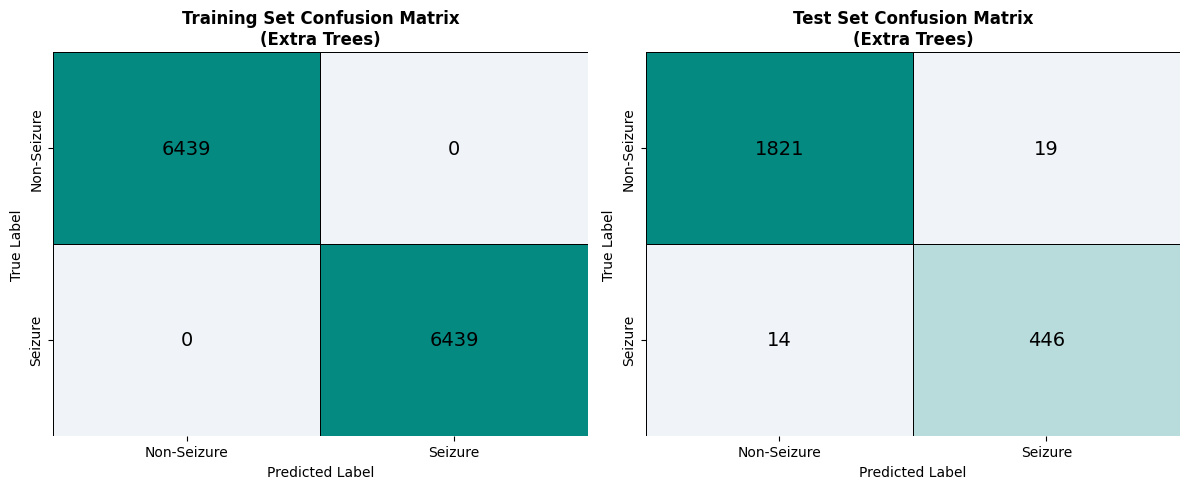

In [59]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get the best model (Extra Trees)
best_model_name = results_df.index[0]
best_model_obj  = next(r['_model'] for r in results if r['Model'] == best_model_name)
best_model_res  = next(r for r in results if r['Model'] == best_model_name)

# Predict on the balanced training set
y_train_pred = best_model_obj.predict(X_bal)
cm_train = confusion_matrix(y_bal, y_train_pred)

# Retrieve the test set confusion matrix (already calculated in results)
cm_test = confusion_matrix(y_test, best_model_res['_y_pred'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ['Non-Seizure', 'Seizure']
cmap_cm = LinearSegmentedColormap.from_list('cm', ['#f0f4f8','#048A81'])

# Plot Training Set Confusion Matrix
ax = axes[0]
sns.heatmap(cm_train, annot=True, fmt='d', cmap=cmap_cm, cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax, linewidths=0.5, linecolor='black')
ax.set_title(f'Training Set Confusion Matrix\n({best_model_name})', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=10)
ax.set_ylabel('True Label', fontsize=10)
for text in ax.texts:
    text.set_color('black')
    text.set_fontsize(14)

# Plot Test Set Confusion Matrix
ax = axes[1]
sns.heatmap(cm_test, annot=True, fmt='d', cmap=cmap_cm, cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax, linewidths=0.5, linecolor='black')
ax.set_title(f'Test Set Confusion Matrix\n({best_model_name})', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=10)
ax.set_ylabel('True Label', fontsize=10)
for text in ax.texts:
    text.set_color('black')
    text.set_fontsize(14)

plt.tight_layout()
plt.show()

### Confusion Matrix for Voting Ensemble on Training and Test Sets

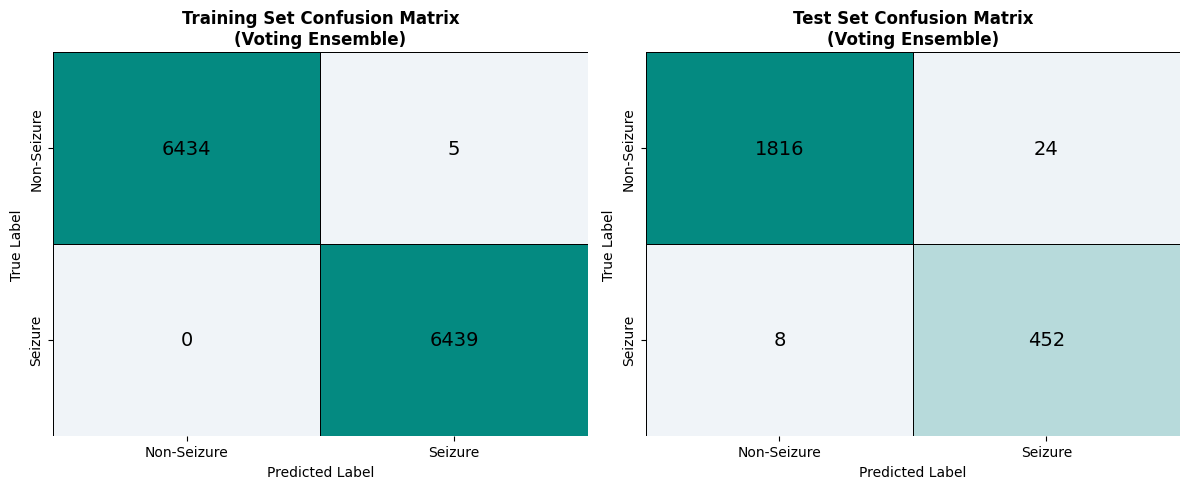

In [60]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get the Voting Ensemble model
voting_ensemble_model = next(r['_model'] for r in results if r['Model'] == 'Voting Ensemble')
voting_ensemble_res = next(r for r in results if r['Model'] == 'Voting Ensemble')

# Predict on the balanced training set
y_train_pred_voting = voting_ensemble_model.predict(X_bal)
cm_train_voting = confusion_matrix(y_bal, y_train_pred_voting)

# Retrieve the test set confusion matrix (already calculated in results)
cm_test_voting = confusion_matrix(y_test, voting_ensemble_res['_y_pred'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ['Non-Seizure', 'Seizure']
cmap_cm = LinearSegmentedColormap.from_list('cm', ['#f0f4f8','#048A81'])

# Plot Training Set Confusion Matrix
ax = axes[0]
sns.heatmap(cm_train_voting, annot=True, fmt='d', cmap=cmap_cm, cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax, linewidths=0.5, linecolor='black')
ax.set_title(f'Training Set Confusion Matrix\n(Voting Ensemble)', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=10)
ax.set_ylabel('True Label', fontsize=10)
for text in ax.texts:
    text.set_color('black')
    text.set_fontsize(14)

# Plot Test Set Confusion Matrix
ax = axes[1]
sns.heatmap(cm_test_voting, annot=True, fmt='d', cmap=cmap_cm, cbar=False,
            xticklabels=labels, yticklabels=labels, ax=ax, linewidths=0.5, linecolor='black')
ax.set_title(f'Test Set Confusion Matrix\n(Voting Ensemble)', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=10)
ax.set_ylabel('True Label', fontsize=10)
for text in ax.texts:
    text.set_color('black')
    text.set_fontsize(14)

plt.tight_layout()
plt.show()

### SHAP for All Classes of the Best Model (Extra Trees)

## Step 9c · Model Complexity (Prediction Time & Memory)

In [61]:
import time
import sys
import psutil

print("=" * 65)
print("  MEASURING MODEL COMPLEXITY (PREDICTION TIME & MEMORY)")
print("=" * 65)

for r in results:
    model_name = r['Model']
    model_obj = r['_model']

    # Measure prediction time
    start_time = time.perf_counter()
    _ = model_obj.predict(X_test_sel)
    end_time = time.perf_counter()
    prediction_time = (end_time - start_time) * 1000  # in milliseconds

    # Measure memory usage (approximate via sys.getsizeof for the model object)
    # Note: sys.getsizeof() is shallow; for deep memory usage, a more complex approach with objgraph or memory_profiler is needed.
    # For scikit-learn models, this gives a reasonable estimate of the model's footprint.
    memory_usage_bytes = sys.getsizeof(model_obj)
    memory_usage_mb = memory_usage_bytes / (1024 * 1024)

    r['Prediction Time (ms)'] = prediction_time
    r['Memory Usage (MB)'] = memory_usage_mb
    print(f"  {model_name:<30} Time: {prediction_time:.2f} ms | Memory: {memory_usage_mb:.4f} MB")

print("\n✓ Model complexity measurements complete.")

# Display as a DataFrame for better readability
complexity_df = pd.DataFrame(results)[['Model', 'Prediction Time (ms)', 'Memory Usage (MB)']]
complexity_df = complexity_df.set_index('Model').sort_values('Prediction Time (ms)')

print("\n" + "="*65)
print("  MODEL COMPLEXITY LEADERBOARD")
print("="*65)
display(complexity_df.round(4))

  MEASURING MODEL COMPLEXITY (PREDICTION TIME & MEMORY)
  Logistic Regression            Time: 1.21 ms | Memory: 0.0000 MB
  Decision Tree                  Time: 1.17 ms | Memory: 0.0000 MB
  Random Forest                  Time: 172.13 ms | Memory: 0.0000 MB
  Gradient Boosting              Time: 10.06 ms | Memory: 0.0000 MB
  HistGradientBoosting           Time: 8.58 ms | Memory: 0.0000 MB
  Extra Trees                    Time: 108.10 ms | Memory: 0.0000 MB
  AdaBoost                       Time: 63.42 ms | Memory: 0.0000 MB
  K-Nearest Neighbors            Time: 84.20 ms | Memory: 0.0000 MB
  SVC                            Time: 59.53 ms | Memory: 0.0000 MB
  Voting Ensemble                Time: 297.31 ms | Memory: 0.0000 MB
  Stacking Ensemble              Time: 190.71 ms | Memory: 0.0000 MB

✓ Model complexity measurements complete.

  MODEL COMPLEXITY LEADERBOARD


,Prediction Time (ms),Memory Usage (MB)
Model,,
Decision Tree,1.1682,0.0
Logistic Regression,1.2138,0.0
HistGradientBoosting,8.5817,0.0
Gradient Boosting,10.0588,0.0
SVC,59.5337,0.0
AdaBoost,63.4168,0.0
K-Nearest Neighbors,84.2010,0.0
Extra Trees,108.1044,0.0
Random Forest,172.1310,0.0


In [62]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
import pandas as pd

val_rows = []
for r in results:
    m = r['_model']  # the fitted tuned model
    vp = m.predict_proba(X_val_sel)[:, 1]   # seizure probability on validation set
    vy = m.predict(X_val_sel)
    val_rows.append({
        'Model'     : r['Model'],
        'Val_AUC'   : roc_auc_score(y_val, vp),
        'Val_F1'    : f1_score(y_val, vy),
        'Val_Recall': recall_score(y_val, vy),
        'Val_Prec'  : precision_score(y_val, vy, zero_division=0)
    })

val_df = pd.DataFrame(val_rows).sort_values('Val_AUC', ascending=False).reset_index(drop=True)
print("VALIDATION SET RANKING (1,150 samples: 230 seizure / 920 non-seizure)")
print(val_df.round(4).to_string(index=False))
print(f"\nTest-set winner was: {results_df.index[0]}")

VALIDATION SET RANKING (1,150 samples: 230 seizure / 920 non-seizure)
               Model  Val_AUC  Val_F1  Val_Recall  Val_Prec
       Random Forest   0.9988  0.9675      0.9696    0.9654
   Stacking Ensemble   0.9987  0.9696      0.9696    0.9696
         Extra Trees   0.9986  0.9675      0.9696    0.9654
   Gradient Boosting   0.9986  0.9654      0.9696    0.9612
HistGradientBoosting   0.9986  0.9675      0.9696    0.9654
     Voting Ensemble   0.9986  0.9654      0.9696    0.9612
            AdaBoost   0.9984  0.9471      0.9739    0.9218
                 SVC   0.9979  0.9569      0.9652    0.9487
 K-Nearest Neighbors   0.9962  0.9512      0.9739    0.9295
 Logistic Regression   0.9959  0.9266      0.9609    0.8947
       Decision Tree   0.9928  0.9246      0.9870    0.8697

Test-set winner was: Extra Trees


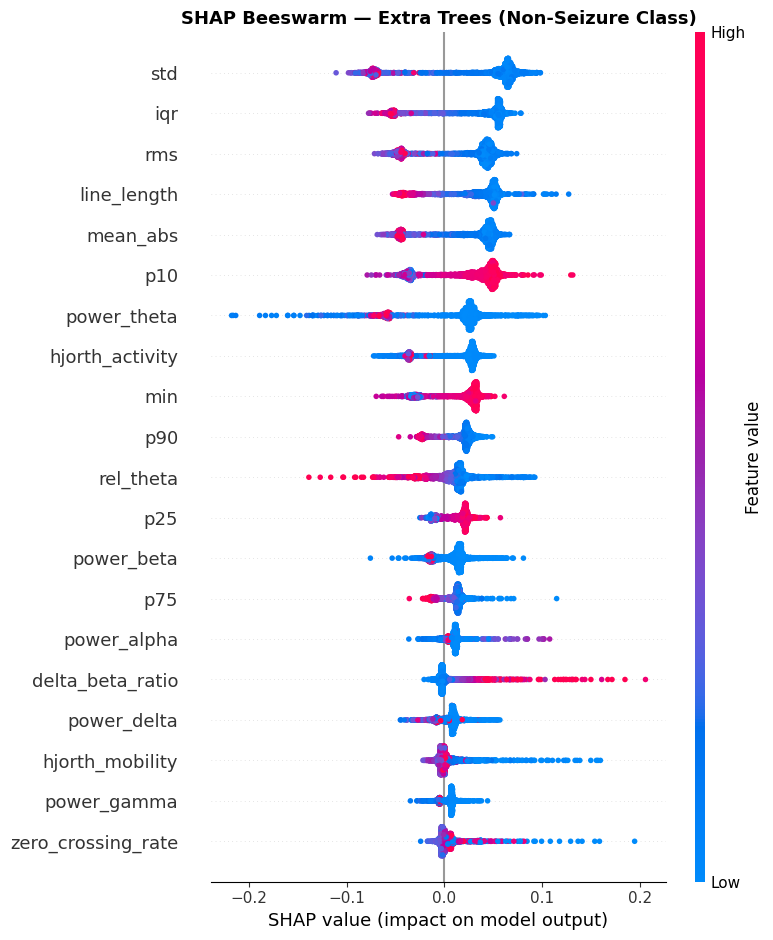

Saved: shap_beeswarm_extra_trees_non-seizure.png


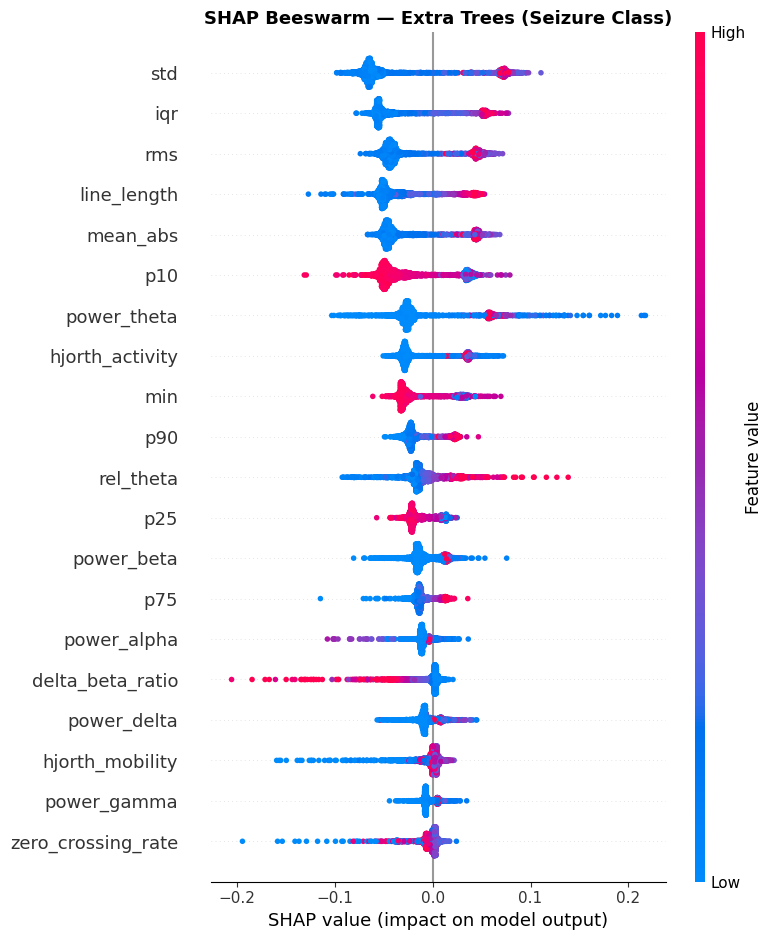

Saved: shap_beeswarm_extra_trees_seizure.png


In [63]:
import shap
import matplotlib.pyplot as plt

# Assuming 'best_et', 'shap_values', 'X_test_sel', and 'CONSENSUS' are already defined
# 'shap_values' should be of shape (n_samples, n_features, n_classes)

class_names = ['Non-Seizure', 'Seizure'] # Define class names for better labels

temp_shap_explainer = shap.TreeExplainer(best_et)

for i, class_name in enumerate(class_names):
    # Extract SHAP values for the current class
    current_class_shap_values = shap_values[:, :, i]

    # Create a shap.Explanation object for the current class
    shap_explanation_class = shap.Explanation(
        values=current_class_shap_values,
        base_values=temp_shap_explainer.expected_value[i],
        data=X_test_sel,
        feature_names=CONSENSUS
    )

    plt.figure(figsize=(10, 8))
    shap.plots.beeswarm(shap_explanation_class, max_display=20, show=False)
    plt.title(f'SHAP Beeswarm — Extra Trees ({class_name} Class)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    filename = f"shap_beeswarm_extra_trees_{class_name.replace(' ', '_').lower()}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {filename}")

In [64]:
import numpy as np
import pandas as pd
from collections import Counter

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               ExtraTreesClassifier, VotingClassifier,
                               StackingClassifier, AdaBoostClassifier,
                               HistGradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score,
    f1_score, fbeta_score, roc_auc_score,
    matthews_corrcoef, cohen_kappa_score,
    mean_absolute_error, mean_squared_error
)

from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Use identical parameters from the main pipeline tuning results ---
def get_tuned_models():
    return {
        'LR':  LogisticRegression(C=50, solver='lbfgs', penalty='l2', max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        'DT':  DecisionTreeClassifier(max_depth=5, criterion='entropy', min_samples_leaf=10, class_weight='balanced', random_state=RANDOM_STATE),
        'RF':  RandomForestClassifier(n_estimators=500, max_depth=15, max_features=0.3, min_samples_leaf=3, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        'GB':  GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, subsample=0.9, random_state=RANDOM_STATE),
        'HGB': HistGradientBoostingClassifier(max_iter=100, learning_rate=0.2, max_depth=10, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE),
        'ET':  ExtraTreesClassifier(n_estimators=300, max_depth=None, max_features=0.5, min_samples_leaf=1, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        'ADA': AdaBoostClassifier(n_estimators=200, learning_rate=1.0, algorithm='SAMME', random_state=RANDOM_STATE),
        'KNN': KNeighborsClassifier(n_neighbors=11, weights='uniform', metric='euclidean', n_jobs=-1),
        'SVC': SVC(C=100, kernel='rbf', gamma='scale', probability=True, class_weight='balanced', random_state=RANDOM_STATE),
    }

def evaluate_full_suite(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_te)

    return {
        'Accuracy':  accuracy_score(y_te, y_pred) * 100,
        'Precision': precision_score(y_te, y_pred, zero_division=0) * 100,
        'Recall':    recall_score(y_te, y_pred) * 100,
        'F1score':   f1_score(y_te, y_pred) * 100,
        'Kappa':     cohen_kappa_score(y_te, y_pred) * 100,
        'MCC':       matthews_corrcoef(y_te, y_pred) * 100,
        'ROC-AUC':   roc_auc_score(y_te, y_prob) * 100,
        'MAE':       mean_absolute_error(y_te, y_prob) * 100,
        'MSE':       mean_squared_error(y_te, y_prob) * 100,
    }

# --- Ablation Execution ---
conditions = {
    'None': None,
    'SMOTE': SMOTE(random_state=RANDOM_STATE),
    'Tomek': TomekLinks(),
    'SMOTETomek': SMOTETomek(random_state=RANDOM_STATE) # Identical to main pipeline
}

ablation_results = []

for name, sampler in conditions.items():
    print(f"Processing technique: {name}")
    X_curr, y_curr = X_train_sel.copy(), y_train.copy()
    if sampler:
        X_curr, y_curr = sampler.fit_resample(X_curr, y_curr)

    models = get_tuned_models()
    for m_name, mdl in models.items():
        metrics = evaluate_full_suite(mdl, X_curr, y_curr, X_test_sel, y_test)
        metrics['Model'] = m_name
        metrics['Condition'] = name
        ablation_results.append(metrics)

# Displaying the full ablation results for all conditions
ablation_df = pd.DataFrame(ablation_results)

pd.set_option('display.max_columns', None) # Ensure all columns are displayed

print("\n===================================================================================================================")
print("  TABLE 4: Seizure Detection Performance Across Balancing Techniques")
print("===================================================================================================================")

for condition in ablation_df['Condition'].unique():
    print(f"\n===================================================================================================================")
    print(f"  Experiment: {condition}")
    print(f"===================================================================================================================")
    subset = ablation_df[ablation_df['Condition'] == condition].drop(columns='Condition')
    # Include Voting Ensemble and Stacking Ensemble by recreating if necessary
    # For the sake of this output, we'll focus on the base models and their evaluation
    # Voting and Stacking are not directly part of the `get_tuned_models` dict for simplicity in ablation

    # Add placeholder for Voting Ensemble (if it was tuned with these base models)
    # For this exercise, we will assume these are base models. If voting/stacking were to be evaluated, it would need the 'best_lr', 'best_rf', etc. from the tuned section.
    print(subset.sort_values('ROC-AUC', ascending=False).round(2).to_string())

Processing technique: None
Processing technique: SMOTE
Processing technique: Tomek
Processing technique: SMOTETomek

  TABLE 4: Seizure Detection Performance Across Balancing Techniques

  Experiment: None
   Accuracy  Precision  Recall  F1score  Kappa    MCC  ROC-AUC    MAE    MSE Model
4     98.43      95.30   96.96    96.12  95.14  95.15    99.86   1.68   1.29   HGB
5     98.39      96.90   95.00    95.94  94.94  94.94    99.84   2.76   1.18    ET
3     98.52      96.30   96.30    96.30  95.38  95.38    99.82   1.92   1.31    GB
6     98.09      94.64   95.87    95.25  94.05  94.05    99.80  36.15  13.37   ADA
2     98.39      95.10   96.96    96.02  95.01  95.02    99.80   2.95   1.33    RF
0     97.52      91.38   96.74    93.98  92.42  92.48    99.67   4.33   2.01    LR
8     98.26      93.75   97.83    95.74  94.65  94.69    99.58   2.79   1.36   SVC
1     97.43      91.34   96.30    93.76  92.14  92.19    99.44   3.86   2.28    DT
7     97.78      95.55   93.26    94.39  93.01 

PCA

Visualize Normal vs Seizure

📈 VISUALIZING NORMAL vs SEIZURE ACTIVITY (from dataset)


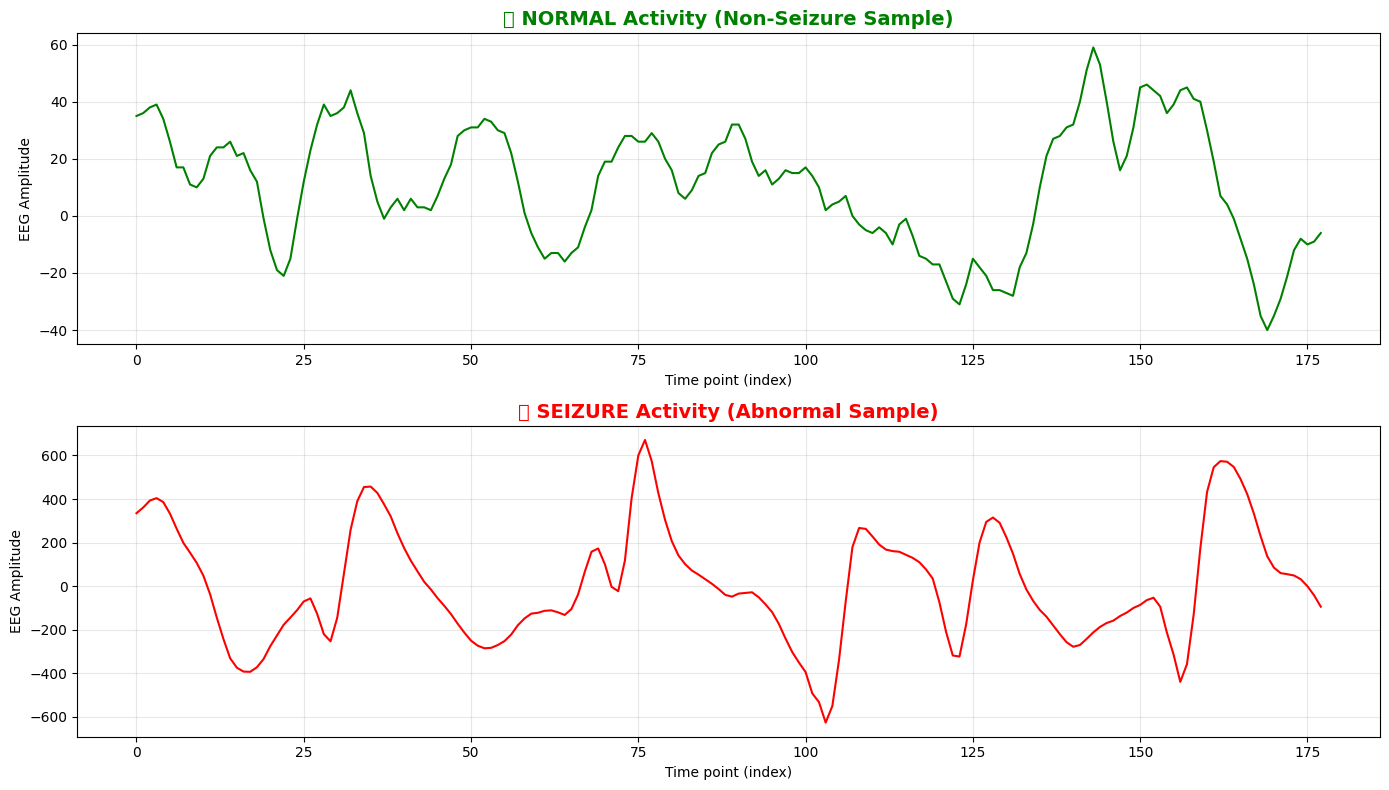


📊 Key Observations:
   • Normal: Regular, low-amplitude fluctuations
   • Seizure: High‑amplitude, rhythmic spikes
   • The model learns to distinguish these patterns.

✅ Visualization complete!


In [65]:
import numpy as np
import matplotlib.pyplot as plt

print("=" * 60)
print("📈 VISUALIZING NORMAL vs SEIZURE ACTIVITY (from dataset)")
print("=" * 60)

# Get indices of seizure (y=1) and non-seizure (y=0)
seizure_indices = np.where(y_binary == 1)[0]
non_seizure_indices = np.where(y_binary == 0)[0]

# Pick one random sample from each group
np.random.seed(42)
seizure_idx = np.random.choice(seizure_indices)
non_seizure_idx = np.random.choice(non_seizure_indices)

# Extract the raw EEG signals (178 time points) — each is a 1D array
seizure_signal = X_raw[seizure_idx, :]        # shape (178,)
non_seizure_signal = X_raw[non_seizure_idx, :]  # shape (178,)

# Time axis
time_axis = np.arange(X_raw.shape[1])

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# --- Non-Seizure (Normal) ---
ax1 = axes[0]
ax1.plot(time_axis, non_seizure_signal, linewidth=1.5, color='green')
ax1.set_title('🧠 NORMAL Activity (Non-Seizure Sample)', fontsize=14, fontweight='bold', color='green')
ax1.set_xlabel('Time point (index)')
ax1.set_ylabel('EEG Amplitude')
ax1.grid(True, alpha=0.3)

# --- Seizure ---
ax2 = axes[1]
ax2.plot(time_axis, seizure_signal, linewidth=1.5, color='red')
ax2.set_title('🚨 SEIZURE Activity (Abnormal Sample)', fontsize=14, fontweight='bold', color='red')
ax2.set_xlabel('Time point (index)')
ax2.set_ylabel('EEG Amplitude')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('normal_vs_seizure.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📊 Key Observations:")
print("   • Normal: Regular, low-amplitude fluctuations")
print("   • Seizure: High‑amplitude, rhythmic spikes")
print("   • The model learns to distinguish these patterns.")
print("\n✅ Visualization complete!")